# 03 - Greedy Information and Active GP Sampling

This notebook implements greedy and active GP sampling methods on a stationary synthetic field:
- Random baseline
- Fine lawnmower baseline
- Coarse lawnmower baseline
- Krause-style greedy information placement (offline batch)
- Sequential predictive-variance sampling
- Sequential predictive-entropy sampling

It compares reconstruction accuracy, uncertainty, calibration, and path efficiency under common settings.

In [1]:
# -----------------------------
# 0) Imports and project wiring
# -----------------------------

import os
import sys
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import gpytorch

project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.append(project_root)

from src.fields import create_grid, get_field
from src.samplers import random_sampler
from src.metrics import path_length

torch.set_default_dtype(torch.float32)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f'PyTorch device: {device}')

PyTorch device: cpu


## 1) Configuration

Use quick mode for fast validation, then disable it to run full budgets.

In [2]:
# -----------------------------
# 1) Config
# -----------------------------

seed = 11
rng = np.random.default_rng(seed)
torch.manual_seed(seed)

field_name = 'temperature'
noise_std = 0.05
noise_map_seed = 101

evaluation_grid_size = 50
candidate_grid_size = 15

# Baseline stride settings
fine_row_stride, fine_column_stride = 1, 1
coarse_row_stride, coarse_column_stride = 2, 2

# Shared initial pilot for greedy/active methods
initial_pilot = 5

# Budget control
requested_full_budgets = [10, 20, 50, 100]
coarse_capacity = (
    math.ceil(candidate_grid_size / coarse_row_stride) *
    math.ceil(candidate_grid_size / coarse_column_stride)
)
full_budgets = [b for b in requested_full_budgets if b <= coarse_capacity]
quick_mode = True
sample_budgets = [10, 20, 30, 50, 64] if quick_mode else full_budgets

# GP training settings (used by learned/constrained modes)
gp_train_iters = 320
gp_learning_rate = 0.02

# Minimum-distance exclusion radius for active sequential methods.
# Candidate grid spacing is 1/(candidate_grid_size-1) ~ 0.0714, so this must
# exceed it to actually exclude immediate neighbors and enforce non-redundant spacing.
r_min = 0.08

# Fixed kernel hyperparameters for offline greedy and active acquisition
greedy_lengthscale = 0.18
greedy_outputscale = noise_std ** 2  # placeholder, overridden in Section 2
greedy_noise_variance = noise_std ** 2

# Evaluation GP mode: 'fixed', 'constrained', or 'learned'
evaluation_gp_mode = 'fixed'

# For controlled posterior-variance comparison, keep original units.
# If enabling standardization, use one global scale (not per strategy/budget).
standardize_targets = False

print('Budgets:', sample_budgets)
print('Quick mode:', quick_mode)
print('Evaluation GP mode:', evaluation_gp_mode)
print('Standardize targets:', standardize_targets)
print(f'Coarse capacity with current grid/stride: {coarse_capacity}')
if len(full_budgets) < len(requested_full_budgets):
    print(f'Adjusted full_budgets to avoid coarse overflow: {full_budgets}')

Budgets: [10, 20, 30, 50, 64]
Quick mode: True
Evaluation GP mode: fixed
Standardize targets: False
Coarse capacity with current grid/stride: 64
Adjusted full_budgets to avoid coarse overflow: [10, 20, 50]


## 2) Grids and Field Values

Sampling is done on a coarse candidate grid, while evaluation/plots use a denser grid.

In [3]:
# -----------------------------
# 2) Build coarse candidate grid and dense eval grid
# -----------------------------

x_eval, y_eval, x1_eval, x2_eval, eval_points = create_grid(evaluation_grid_size)
eval_field = get_field(field_name, x1_eval, x2_eval)
eval_truth_flat = eval_field.ravel()

x_cand, y_cand, x1_cand, x2_cand, candidate_points = create_grid(candidate_grid_size)
candidate_field = get_field(field_name, x1_cand, x2_cand)

# Fast lookup for candidate measurements
candidate_value_map = {
    (float(p[0]), float(p[1])): float(v)
    for p, v in zip(candidate_points, candidate_field.ravel())
}

# ---------------------------------------------------------------
# Output scale: set from ground-truth field variance for simulation
# validation. In deployment, estimate from pilot measurements:
#   pilot_measurements = noisy_lookup values for pilot_points
#   greedy_outputscale = max(float(np.var(pilot_measurements, ddof=1)), 1e-4)
# ---------------------------------------------------------------
greedy_outputscale = float(np.var(eval_field))

print(f'Eval points: {len(eval_points)}')
print(f'Candidate points: {len(candidate_points)}')
print(f'Synthetic field variance (eval grid): {greedy_outputscale:.4f}')
print(f'greedy_outputscale set to: {greedy_outputscale:.4f}')

Eval points: 2500
Candidate points: 225
Synthetic field variance (eval grid): 0.0622
greedy_outputscale set to: 0.0622


## 3) Helpers

Common helpers for path generation, GP training, prediction, and calibration metrics.

In [4]:
# -----------------------------
# 3) Utilities
# -----------------------------

class ExactGPModel(gpytorch.models.ExactGP):
    def __init__(self, train_x, train_y, likelihood, constrained=False):
        super().__init__(train_x, train_y, likelihood)
        self.mean_module = gpytorch.means.ConstantMean()
        if constrained:
            self.covar_module = gpytorch.kernels.ScaleKernel(
                gpytorch.kernels.RBFKernel(
                    ard_num_dims=2,
                    lengthscale_constraint=gpytorch.constraints.Interval(0.03, 0.6),
                )
            )
        else:
            self.covar_module = gpytorch.kernels.ScaleKernel(
                gpytorch.kernels.RBFKernel(ard_num_dims=2)
            )

    def forward(self, x):
        mean_x = self.mean_module(x)
        covar_x = self.covar_module(x)
        return gpytorch.distributions.MultivariateNormal(mean_x, covar_x)


def lawnmower_with_stride(x_axis, y_axis, n_samples, row_stride=1, column_stride=1):
    x_sub = x_axis[::max(1, int(column_stride))]
    y_sub = y_axis[::max(1, int(row_stride))]

    points = []
    for row_idx, y_val in enumerate(y_sub):
        row_x = x_sub if row_idx % 2 == 0 else x_sub[::-1]
        for x_val in row_x:
            points.append((x_val, y_val))

    path = np.array(points, dtype=float)
    if len(path) < n_samples:
        raise ValueError('Not enough lawnmower points for requested n_samples')
    return path[:n_samples]


def _point_key(p):
    return (round(float(p[0]), 8), round(float(p[1]), 8))


def build_shared_noise_lookup(points, clean_values, noise_sigma, seed_value):
    rng_local = np.random.default_rng(seed_value)
    noise = rng_local.normal(0.0, noise_sigma, size=len(points))
    noisy_values = clean_values + noise
    return {_point_key(p): float(v) for p, v in zip(points, noisy_values)}


def _lookup_with_fallback(mapping, p):
    k_round = _point_key(p)
    if k_round in mapping:
        return mapping[k_round]
    k_raw = (float(p[0]), float(p[1]))
    if k_raw in mapping:
        return mapping[k_raw]
    raise KeyError(f'Point not found in lookup: {k_raw}')


def measure_candidate_points(points, noisy_lookup):
    clean = np.array([_lookup_with_fallback(candidate_value_map, p) for p in points], dtype=float)
    noisy = np.array([_lookup_with_fallback(noisy_lookup, p) for p in points], dtype=float)
    return clean, noisy


def _predict_and_metrics(model, likelihood, test_x, y_mean, y_std):
    with torch.no_grad(), gpytorch.settings.fast_pred_var():
        latent = model(test_x)
        mean_s = latent.mean
        var_s = latent.variance
        predictive = likelihood(model(test_x))
        pred_var_s = predictive.variance

    pred_mean = (mean_s * y_std + y_mean).detach().cpu().numpy()
    pred_var = (var_s * (y_std ** 2)).detach().cpu().numpy()
    predictive_var = (pred_var_s * (y_std ** 2)).detach().cpu().numpy()

    pred_std = np.sqrt(np.maximum(pred_var, 1e-12))
    rmse = float(np.sqrt(np.mean((pred_mean - eval_truth_flat) ** 2)))
    mean_var = float(np.mean(pred_var))
    mean_entropy = float(np.mean(0.5 * np.log(2.0 * np.pi * np.e * np.maximum(pred_var, 1e-12))))

    abs_error = np.abs(pred_mean - eval_truth_flat)
    corr = float(np.corrcoef(abs_error, pred_std)[0, 1])

    lower = pred_mean - 1.96 * pred_std
    upper = pred_mean + 1.96 * pred_std
    coverage_95 = float(np.mean((eval_truth_flat >= lower) & (eval_truth_flat <= upper)))

    z = (eval_truth_flat - pred_mean) / np.maximum(pred_std, 1e-8)
    z_mean = float(np.mean(z))

    lengthscale = model.covar_module.base_kernel.lengthscale.detach().cpu().numpy().ravel()
    outputscale = float(model.covar_module.outputscale.detach().cpu().item())
    noise_var = float(likelihood.noise.detach().cpu().item())
    mean_constant_scaled = float(model.mean_module.constant.detach().cpu().item())
    mean_constant = float(mean_constant_scaled * y_std.item() + y_mean.item())

    return {
        'mean': pred_mean,
        'var': pred_var,
        'predictive_var': predictive_var,
        'std': pred_std,
        'rmse': rmse,
        'mean_var': mean_var,
        'mean_entropy': mean_entropy,
        'abs_error': abs_error,
        'corr_err_unc': corr,
        'coverage_95': coverage_95,
        'z_mean': z_mean,
        'lengthscale': float(np.mean(lengthscale)),
        'lengthscale_ard': lengthscale,
        'outputscale': outputscale,
        'noise_var': noise_var,
        'mean_constant': mean_constant,
    }


def fit_gp_predict(train_points, train_values, mode='learned', standardize=True):
    train_x = torch.tensor(train_points, dtype=torch.float32, device=device)
    train_y = torch.tensor(train_values, dtype=torch.float32, device=device)
    test_x = torch.tensor(eval_points, dtype=torch.float32, device=device)

    if standardize:
        y_mean = train_y.mean()
        y_std = train_y.std().clamp_min(1e-6)
        train_y_model = (train_y - y_mean) / y_std
    else:
        y_mean = torch.tensor(0.0, dtype=torch.float32, device=device)
        y_std = torch.tensor(1.0, dtype=torch.float32, device=device)
        train_y_model = train_y

    constrained = (mode == 'constrained')
    if constrained:
        likelihood = gpytorch.likelihoods.GaussianLikelihood(
            noise_constraint=gpytorch.constraints.Interval(1e-4, 0.02)
        ).to(device)
    else:
        likelihood = gpytorch.likelihoods.GaussianLikelihood().to(device)

    model = ExactGPModel(train_x, train_y_model, likelihood, constrained=constrained).to(device)

    model.covar_module.base_kernel.lengthscale = greedy_lengthscale
    model.covar_module.outputscale = greedy_outputscale
    likelihood.noise = greedy_noise_variance
    model.mean_module.constant = train_y_model.mean()

    if mode == 'fixed':
        model.covar_module.base_kernel.raw_lengthscale.requires_grad_(False)
        model.covar_module.raw_outputscale.requires_grad_(False)
        likelihood.raw_noise.requires_grad_(False)

        model.eval()
        likelihood.eval()
        return _predict_and_metrics(model, likelihood, test_x, y_mean, y_std)

    model.train()
    likelihood.train()
    optimizer = torch.optim.Adam(model.parameters(), lr=gp_learning_rate)
    mll = gpytorch.mlls.ExactMarginalLogLikelihood(likelihood, model)

    for _ in range(gp_train_iters):
        optimizer.zero_grad()
        output = model(train_x)
        loss = -mll(output, train_y_model)
        loss.backward()
        optimizer.step()

    model.eval()
    likelihood.eval()
    return _predict_and_metrics(model, likelihood, test_x, y_mean, y_std)


def pairwise_sq_dists(a, b):
    a2 = np.sum(a * a, axis=1, keepdims=True)
    b2 = np.sum(b * b, axis=1, keepdims=True).T
    return np.maximum(a2 + b2 - 2.0 * a @ b.T, 0.0)


def rbf_covariance(a, b, lengthscale, outputscale):
    d2 = pairwise_sq_dists(a, b)
    return outputscale * np.exp(-0.5 * d2 / (lengthscale ** 2))


def fixed_posterior_variance(train_points, query_points):
    if len(train_points) == 0:
        k_qq = rbf_covariance(query_points, query_points, greedy_lengthscale, greedy_outputscale)
        return np.maximum(np.diag(k_qq), 1e-12)

    k_xx = rbf_covariance(train_points, train_points, greedy_lengthscale, greedy_outputscale)
    k_xx = k_xx + greedy_noise_variance * np.eye(len(train_points))
    k_qx = rbf_covariance(query_points, train_points, greedy_lengthscale, greedy_outputscale)
    k_qq_diag = np.diag(rbf_covariance(query_points, query_points, greedy_lengthscale, greedy_outputscale))

    solve_term = np.linalg.solve(k_xx, k_qx.T)
    var = k_qq_diag - np.sum(k_qx * solve_term.T, axis=1)
    return np.maximum(var, 1e-12)

## 4) Krause-Style Greedy Information Placement (Offline Batch)

This uses the **mutual-information** criterion of Krause et al. (2008),
*Near-Optimal Sensor Placements in Gaussian Processes*. At each step we add the
candidate with the largest greedy MI gain:

$$\delta(y)=\tfrac{1}{2}\log\frac{\sigma^2(y\mid A)}{\sigma^2\!\left(y\mid V\setminus(A\cup\{y\})\right)}$$

where $\sigma^2(y\mid A)$ is the posterior variance at $y$ given the points already
selected, and the denominator is the posterior variance at $y$ given **all other**
candidate locations.

Maximizing this *ratio* (not raw variance) is what separates MI placement from
pure max-variance / entropy selection. Border and corner points have high raw
variance, but they are also highly uncertain with respect to the unobserved set
(few neighbors), so the ratio is small there. The criterion therefore pulls
selections into the informative interior instead of clustering on the boundary.


In [5]:
# -----------------------------
# 4) Greedy MUTUAL INFORMATION sampler (Krause et al., 2008)
# -----------------------------
# Greedy MI gain for adding candidate y to the selected set A:
#   delta(y) = 0.5 * log( sigma^2(y | A) / sigma^2(y | V \ (A u {y})) )
#
# - Numerator   sigma^2(y | A):  posterior variance at y given selected points.
# - Denominator sigma^2(y | V \ (A u {y})): variance at y given ALL other
#   candidate locations. Computed efficiently via the precision trick:
#   conditioning a joint Gaussian on all-but-one coordinate gives
#   var_i = 1 / (Sigma^{-1})_ii, where Sigma is the posterior covariance of the
#   available points given A.
#
# Maximizing the ratio penalizes border/corner points (also uncertain w.r.t. the
# unobserved set) and favors the interior -- this is what makes MI placement
# distinct from, and better than, pure max-variance / entropy selection.

K_all = rbf_covariance(candidate_points, candidate_points, greedy_lengthscale, greedy_outputscale)


def greedy_information_sampler(n_samples, initial_indices=None):
    selected = [] if initial_indices is None else list(initial_indices)
    n_cand = len(candidate_points)
    jitter = 1e-8

    gains = []
    objectives = []
    current_obj = 0.0

    while len(selected) < n_samples:
        selected_set = set(selected)
        available = np.array([i for i in range(n_cand) if i not in selected_set], dtype=int)

        # Posterior covariance of the available points given the current selection A.
        if len(selected) == 0:
            sigma_av = K_all[np.ix_(available, available)].astype(float).copy()
        else:
            A = np.array(selected, dtype=int)
            k_AA = K_all[np.ix_(A, A)] + greedy_noise_variance * np.eye(len(A))
            k_vA = K_all[np.ix_(available, A)]
            sigma_av = K_all[np.ix_(available, available)] - k_vA @ np.linalg.solve(k_AA, k_vA.T)

        # Numerator: sigma^2(y | A) for every available y.
        var_given_A = np.maximum(np.diag(sigma_av), 1e-12)

        # Denominator: sigma^2(y | all other available points) = 1 / precision_ii.
        precision = np.linalg.inv(sigma_av + jitter * np.eye(len(available)))
        var_given_rest = np.maximum(1.0 / np.diag(precision), 1e-12)

        gain_all = 0.5 * np.log(var_given_A / var_given_rest)
        best_pos = int(np.argmax(gain_all))
        best_i = int(available[best_pos])

        selected.append(best_i)
        current_obj += float(gain_all[best_pos])
        gains.append(float(gain_all[best_pos]))
        objectives.append(float(current_obj))

    selected_points = candidate_points[selected]
    return selected, selected_points, np.array(gains), np.array(objectives)


## 5) Sequential Online Active Sampling

Methods:
- Variance acquisition: $a_t(x)=\sigma_t^2(x)$
- Entropy acquisition: $H_t(x)=\frac{1}{2}\log(2\pi e\,\sigma_t^2(x))$

For this controlled comparison, acquisition uses fixed stationary kernel hyperparameters (same family as greedy information placement). This makes variance and entropy directly comparable and removes hyperparameter drift during selection.

In [6]:
# -----------------------------
# 5) Active samplers (variance / entropy)
# -----------------------------

def min_distance_mask(points, selected_points, min_dist):
    if len(selected_points) == 0:
        return np.ones(len(points), dtype=bool)
    s = np.array(selected_points)
    d2 = pairwise_sq_dists(points, s)
    dmin = np.sqrt(np.min(d2, axis=1))
    return dmin > min_dist


def sequential_active_sampler(n_samples, acquisition='variance', initial_points=None, noisy_lookup=None):
    if initial_points is None:
        initial_points = candidate_points[[0, len(candidate_points)//2]]

    if noisy_lookup is None:
        raise ValueError('noisy_lookup is required for controlled comparisons')

    selected = [np.array(p, dtype=float) for p in initial_points]
    _, noisy = measure_candidate_points(np.array(selected), noisy_lookup)
    train_y = noisy.tolist()

    gains_trace = []

    while len(selected) < n_samples:
        X_train = np.array(selected, dtype=float)
        var_all = fixed_posterior_variance(X_train, candidate_points)

        if acquisition == 'variance':
            score = var_all.copy()
        elif acquisition == 'entropy':
            score = 0.5 * np.log(2.0 * np.pi * np.e * var_all)
        else:
            raise ValueError('acquisition must be variance or entropy')

        chosen_set = set(_point_key(p) for p in selected)
        not_chosen = np.array([_point_key(p) not in chosen_set for p in candidate_points], dtype=bool)
        far_enough = min_distance_mask(candidate_points, selected, r_min)
        valid = not_chosen & far_enough

        if not np.any(valid):
            valid = not_chosen

        masked_score = np.where(valid, score, -np.inf)
        next_idx = int(np.argmax(masked_score))

        # Debugging invariant: selected point must be valid argmax under mask
        best_visible_idx = int(np.argmax(np.where(valid, score, -np.inf)))
        assert best_visible_idx == next_idx

        next_point = candidate_points[next_idx]
        _, noisy_val = measure_candidate_points(next_point.reshape(1, 2), noisy_lookup)

        selected.append(next_point)
        train_y.append(float(noisy_val[0]))
        gains_trace.append(float(score[next_idx]))

    return np.array(selected), np.array(train_y), np.array(gains_trace)

## 6) Run All Six Strategies

For each budget, fit the same GP and collect RMSE, uncertainty, entropy, path length, and calibration metrics.

In [7]:
# -----------------------------
# 6) Strategy execution
# -----------------------------

max_budget = max(sample_budgets)

# Shared candidate-domain sample pools
random_pool = random_sampler(candidate_points, n_samples=max_budget, rng=rng)
fine_pool = lawnmower_with_stride(
    x_cand, y_cand, n_samples=max_budget,
    row_stride=fine_row_stride, column_stride=fine_column_stride
)
coarse_pool = lawnmower_with_stride(
    x_cand, y_cand, n_samples=max_budget,
    row_stride=coarse_row_stride, column_stride=coarse_column_stride
)

# Shared initial pilot for greedy and active methods
pilot_indices = rng.choice(len(candidate_points), size=initial_pilot, replace=False)
pilot_points = candidate_points[pilot_indices]

# Offline greedy (single run up to max budget)
greedy_idx, greedy_pool, greedy_marginal_gain, greedy_objective = greedy_information_sampler(
    max_budget, initial_indices=pilot_indices
)

# Build one shared noisy measurement lookup on candidate points
clean_candidate = candidate_field.ravel()
noisy_lookup = build_shared_noise_lookup(
    candidate_points, clean_candidate, noise_std, noise_map_seed
)

# Sequential active sampling. Entropy H(x) = 0.5*log(2*pi*e*sigma^2) is a monotonic
# function of the posterior variance, so entropy and max-variance selection pick the
# identical points for single-point Gaussian acquisition. Per Matthew, we keep one
# method and call it 'Entropy' for now; the objectives diverge once path planning is
# added (e.g. batch/joint log-det entropy).
entropy_pool, entropy_noisy_pool, entropy_score_trace = sequential_active_sampler(
    max_budget, acquisition='entropy', initial_points=pilot_points, noisy_lookup=noisy_lookup
)

strategy_pools = {
    'Random': random_pool,
    'Fine lawnmower': fine_pool,
    'Coarse lawnmower': coarse_pool,
    'Greedy information': greedy_pool,
    'Entropy': entropy_pool,
}

# Precompute one noisy pool per strategy and slice consistently per budget
strategy_noisy_pools = {}
for name, pool in strategy_pools.items():
    _, noisy_pool = measure_candidate_points(pool, noisy_lookup)
    strategy_noisy_pools[name] = noisy_pool

all_records = []
final_budget_outputs = {}
budget_outputs = {}

for name, pool in strategy_pools.items():
    noisy_pool = strategy_noisy_pools[name]
    budget_outputs[name] = {}

    for n in sample_budgets:
        points_n = pool[:n]
        noisy_n = noisy_pool[:n]

        gp_out = fit_gp_predict(
            points_n, noisy_n,
            mode=evaluation_gp_mode,
            standardize=standardize_targets,
        )

        rec = {
            'Strategy': name,
            'Samples': n,
            'PathLength': path_length(points_n),
            'RMSE': gp_out['rmse'],
            'MeanVariance': gp_out['mean_var'],
            'MeanEntropy': gp_out['mean_entropy'],
            'LengthScale': gp_out['lengthscale'],
            'OutputScale': gp_out['outputscale'],
            'NoiseVariance': gp_out['noise_var'],
            'MeanConstant': gp_out['mean_constant'],
            'ErrUncCorr': gp_out['corr_err_unc'],
            'Coverage95': gp_out['coverage_95'],
            'MeanZ': gp_out['z_mean'],
        }

        ls_ard = gp_out['lengthscale_ard']
        rec['LengthScale_x'] = float(ls_ard[0]) if len(ls_ard) > 0 else np.nan
        rec['LengthScale_y'] = float(ls_ard[1]) if len(ls_ard) > 1 else np.nan

        if name == 'Greedy information':
            obj_idx = n - initial_pilot - 1
            rec['InfoObjective'] = float(greedy_objective[obj_idx]) if obj_idx >= 0 else np.nan
        else:
            rec['InfoObjective'] = np.nan

        all_records.append(rec)

        budget_outputs[name][n] = {
            'points': points_n,
            'mean': gp_out['mean'],
            'var': gp_out['var'],
            'predictive_var': gp_out['predictive_var'],
            'std': gp_out['std'],
            'abs_error': gp_out['abs_error'],
        }

        if n == max_budget:
            final_budget_outputs[name] = budget_outputs[name][n]

results_df = pd.DataFrame(all_records)
results_df.head()

,Strategy,Samples,PathLength,RMSE,MeanVariance,MeanEntropy,LengthScale,OutputScale,NoiseVariance,MeanConstant,ErrUncCorr,Coverage95,MeanZ,LengthScale_x,LengthScale_y,InfoObjective
0,Random,10,6.702413,0.283097,0.034865,-0.407002,0.18,0.062177,0.0025,0.107566,0.601596,0.8472,0.658514,0.18,0.18,NaN
1,Random,20,13.469844,0.270783,0.022909,-0.689335,0.18,0.062177,0.0025,0.121826,0.687353,0.8028,0.782323,0.18,0.18,NaN
2,Random,30,17.148892,0.078760,0.010005,-1.106111,0.18,0.062177,0.0025,0.208612,0.440092,0.9888,0.080351,0.18,0.18,NaN
3,Random,50,26.859651,0.053528,0.005519,-1.435783,0.18,0.062177,0.0025,0.253130,0.586926,0.9952,-0.050039,0.18,0.18,NaN
4,Random,64,33.972806,0.050582,0.004295,-1.597363,0.18,0.062177,0.0025,0.236001,0.626478,0.9860,0.025155,0.18,0.18,NaN


## 7) Metric Tables

Budget-wise metrics and a final-budget ranking by RMSE.

In [8]:
# -----------------------------
# 7) Tables
# -----------------------------

display(results_df.sort_values(['Samples', 'RMSE']).reset_index(drop=True))

final_table = results_df[results_df['Samples'] == max_budget].copy()
final_table = final_table.sort_values('RMSE').reset_index(drop=True)
display(
    final_table[[
        'Strategy', 'Samples', 'RMSE', 'MeanVariance', 'MeanEntropy',
        'PathLength', 'LengthScale_x', 'LengthScale_y', 'OutputScale',
        'NoiseVariance', 'MeanConstant', 'ErrUncCorr', 'Coverage95', 'MeanZ'
    ]]
)

# Smart-method comparison. Entropy selection is equivalent to max-variance selection
# (entropy is a monotonic function of variance), so we keep a single 'Entropy' method.
# Greedy information uses the Krause mutual-information criterion and differs from it.
smart_cols = ['PathLength', 'RMSE', 'MeanVariance', 'LengthScale', 'NoiseVariance', 'Coverage95', 'MeanZ']
smart_rows = final_table[final_table['Strategy'].isin(['Greedy information', 'Entropy'])]
smart_comparison_table = smart_rows[['Strategy'] + smart_cols].reset_index(drop=True)
display(smart_comparison_table)

,Strategy,Samples,PathLength,RMSE,MeanVariance,MeanEntropy,LengthScale,OutputScale,NoiseVariance,MeanConstant,ErrUncCorr,Coverage95,MeanZ,LengthScale_x,LengthScale_y,InfoObjective
0,Greedy information,10,4.591142,0.194099,0.025657,-0.528021,0.18,0.062177,0.0025,0.218197,0.079130,0.8084,0.420825,0.18,0.18,36.619131
1,Entropy,10,5.801270,0.239581,0.032758,-0.374782,0.18,0.062177,0.0025,0.193495,0.251143,0.8328,0.364204,0.18,0.18,NaN
2,Fine lawnmower,10,0.642857,0.267014,0.053842,-0.114875,0.18,0.062177,0.0025,0.158364,0.201543,0.8824,0.510594,0.18,0.18,NaN
3,Coarse lawnmower,10,1.285714,0.272063,0.049097,-0.220477,0.18,0.062177,0.0025,0.145515,0.341192,0.8828,0.327245,0.18,0.18,NaN
4,Random,10,6.702413,0.283097,0.034865,-0.407002,0.18,0.062177,0.0025,0.107566,0.601596,0.8472,0.658514,0.18,0.18,NaN
5,Greedy information,20,11.337839,0.085667,0.009659,-1.025559,0.18,0.062177,0.0025,0.226328,0.262924,0.9624,0.249600,0.18,0.18,106.305141
6,Entropy,20,12.783723,0.101799,0.011617,-0.887306,0.18,0.062177,0.0025,0.212966,0.274682,0.9376,0.330901,0.18,0.18,NaN
7,Coarse lawnmower,20,2.714286,0.210910,0.037147,-0.573391,0.18,0.062177,0.0025,0.302895,0.637929,0.9596,-0.367406,0.18,0.18,NaN
8,Fine lawnmower,20,1.357143,0.267910,0.049206,-0.240070,0.18,0.062177,0.0025,0.145294,0.340263,0.8740,0.396264,0.18,0.18,NaN
9,Random,20,13.469844,0.270783,0.022909,-0.689335,0.18,0.062177,0.0025,0.121826,0.687353,0.8028,0.782323,0.18,0.18,NaN


,Strategy,Samples,RMSE,MeanVariance,MeanEntropy,PathLength,LengthScale_x,LengthScale_y,OutputScale,NoiseVariance,MeanConstant,ErrUncCorr,Coverage95,MeanZ
0,Coarse lawnmower,64,0.035553,0.001495,-1.835236,9.000000,0.18,0.18,0.062177,0.0025,0.231167,0.152809,0.9796,0.204943
1,Entropy,64,0.044959,0.001581,-1.812890,40.369127,0.18,0.18,0.062177,0.0025,0.225010,0.165413,0.9052,0.439593
2,Greedy information,64,0.046048,0.001960,-1.803261,35.091526,0.18,0.18,0.062177,0.0025,0.246408,0.513760,0.9384,0.259111
3,Random,64,0.050582,0.004295,-1.597363,33.972806,0.18,0.18,0.062177,0.0025,0.236001,0.626478,0.9860,0.025155
4,Fine lawnmower,64,0.227202,0.034888,-0.764597,4.500000,0.18,0.18,0.062177,0.0025,0.319006,0.615424,0.8624,-0.569381


,Strategy,PathLength,RMSE,MeanVariance,LengthScale,NoiseVariance,Coverage95,MeanZ
0,Entropy,40.369127,0.044959,0.001581,0.18,0.0025,0.9052,0.439593
1,Greedy information,35.091526,0.046048,0.001960,0.18,0.0025,0.9384,0.259111


## 7b) Border-Fraction Diagnostic

Krause mutual-information placement should pull samples into the informative interior
rather than clustering on the high-variance border. This quantifies the fraction of
selected points on the candidate-grid edge for random, greedy MI, and entropy.

In [9]:
# -----------------------------
# 7b) Border-fraction diagnostic
# -----------------------------
def border_fraction(points, tol=1e-9):
    x, y = points[:, 0], points[:, 1]
    on_border = (
        (np.abs(x - 0.0) < tol) | (np.abs(x - 1.0) < tol) |
        (np.abs(y - 0.0) < tol) | (np.abs(y - 1.0) < tol)
    )
    return float(np.mean(on_border))

border_rows = []
for name in ['Random', 'Greedy information', 'Entropy']:
    pts_full = strategy_pools[name][:max_budget]
    border_rows.append({'Strategy': name, 'BorderFraction': border_fraction(pts_full)})

border_df = pd.DataFrame(border_rows)
display(border_df)

,Strategy,BorderFraction
0,Random,0.156250
1,Greedy information,0.171875
2,Entropy,0.390625


## 8) Required Curves

Plots:
- RMSE vs sample count
- Average uncertainty vs sample count
- Cumulative path length vs sample count
- RMSE vs cumulative path length

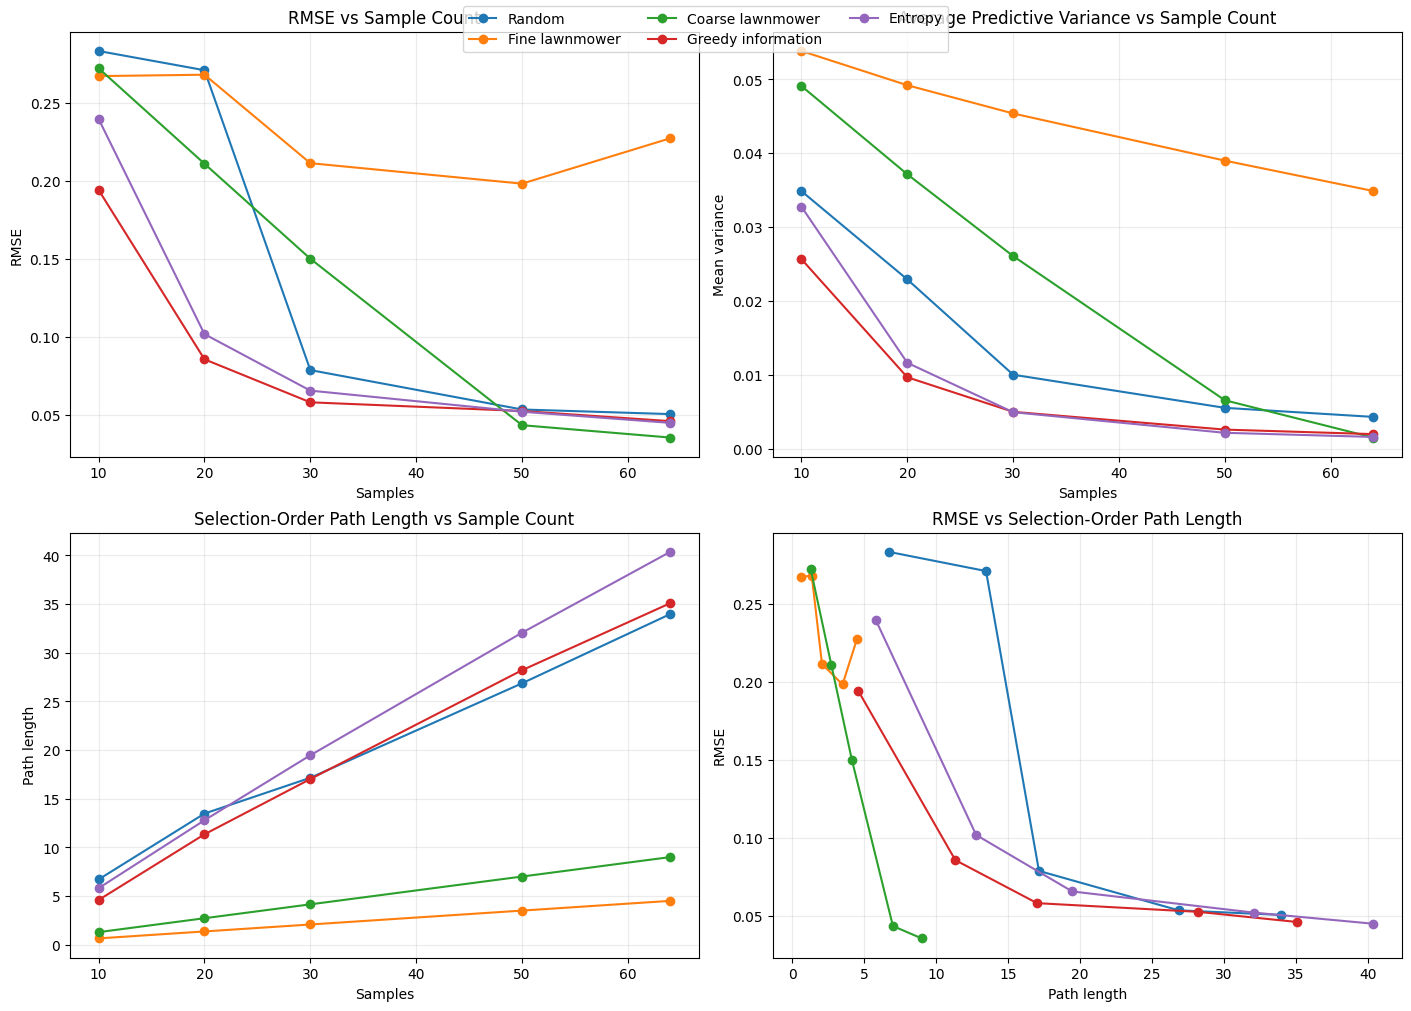

In [10]:
# -----------------------------
# 8) Core comparison curves
# -----------------------------

# Entropy and max-variance selection are equivalent; a single 'Entropy' method is kept.
plot_df = results_df.copy()
strategies = plot_df['Strategy'].unique()

fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)

for s in strategies:
    d = plot_df[plot_df['Strategy'] == s].sort_values('Samples')
    axes[0, 0].plot(d['Samples'], d['RMSE'], marker='o', label=s)
    axes[0, 1].plot(d['Samples'], d['MeanVariance'], marker='o', label=s)
    axes[1, 0].plot(d['Samples'], d['PathLength'], marker='o', label=s)
    axes[1, 1].plot(d['PathLength'], d['RMSE'], marker='o', label=s)

axes[0, 0].set_title('RMSE vs Sample Count')
axes[0, 0].set_xlabel('Samples')
axes[0, 0].set_ylabel('RMSE')
axes[0, 0].grid(alpha=0.25)

axes[0, 1].set_title('Average Predictive Variance vs Sample Count')
axes[0, 1].set_xlabel('Samples')
axes[0, 1].set_ylabel('Mean variance')
axes[0, 1].grid(alpha=0.25)

axes[1, 0].set_title('Selection-Order Path Length vs Sample Count')
axes[1, 0].set_xlabel('Samples')
axes[1, 0].set_ylabel('Path length')
axes[1, 0].grid(alpha=0.25)

axes[1, 1].set_title('RMSE vs Selection-Order Path Length')
axes[1, 1].set_xlabel('Path length')
axes[1, 1].set_ylabel('RMSE')
axes[1, 1].grid(alpha=0.25)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=3)
plt.show()

## 9) Strategy Path Visualizations

Shows selected point order on the coarse candidate grid for all methods at the max budget.

Important: these are unoptimized selection-order paths (not motion-planned routes).

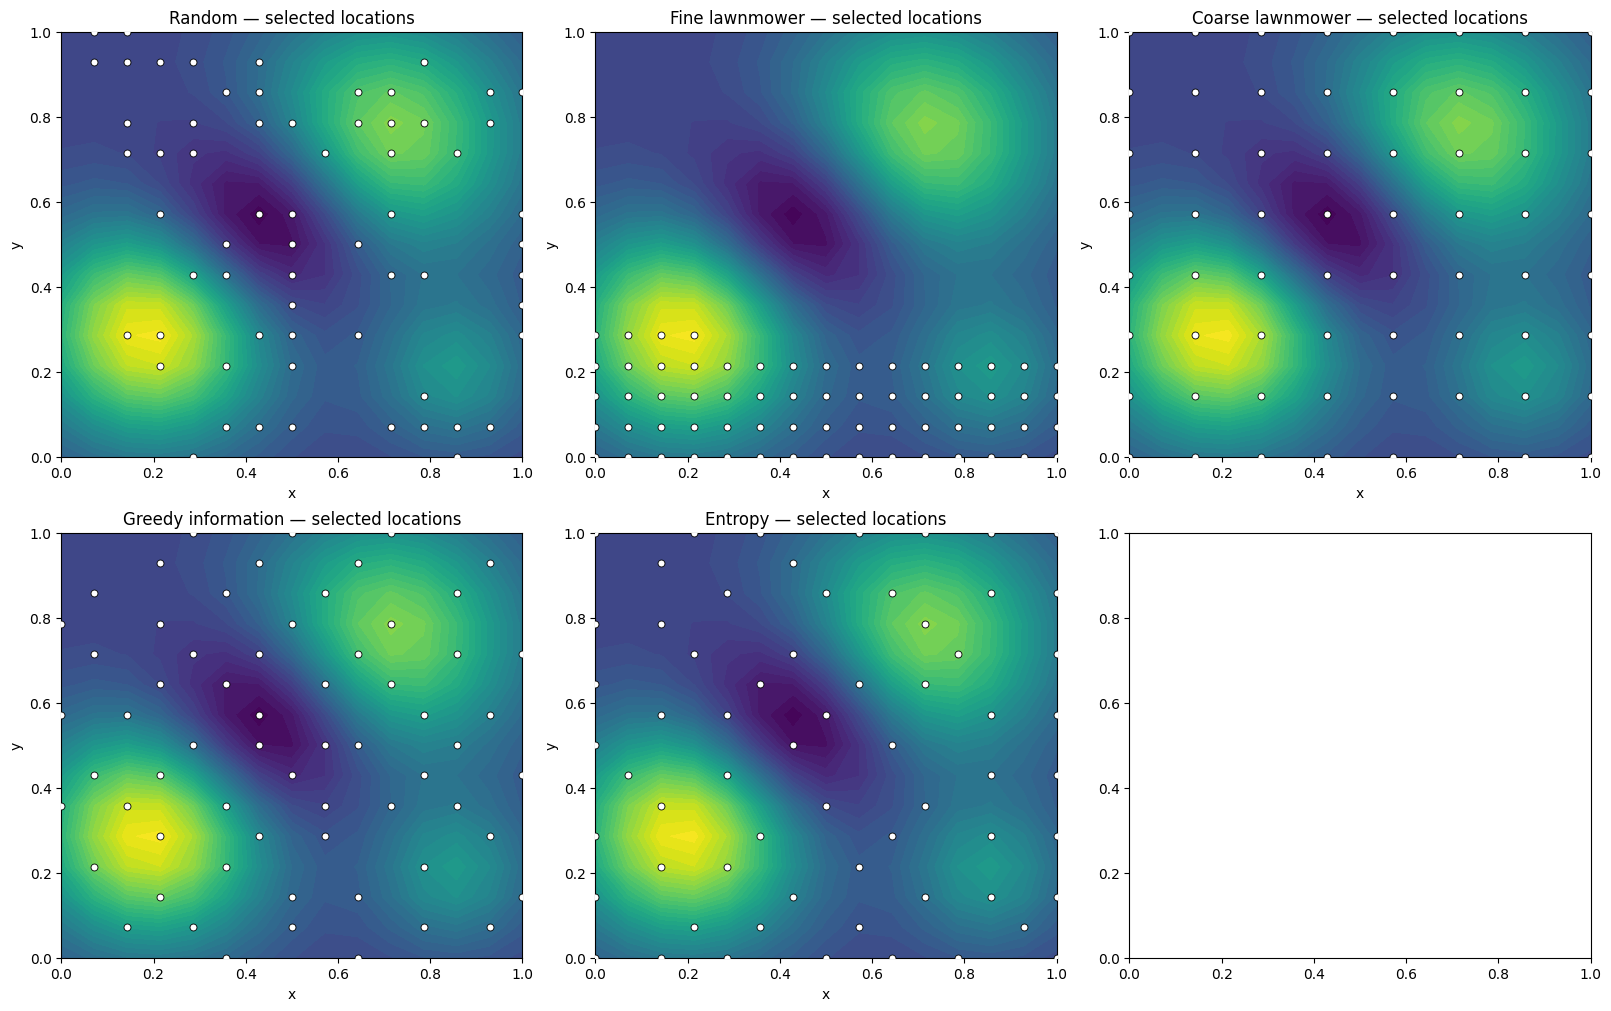

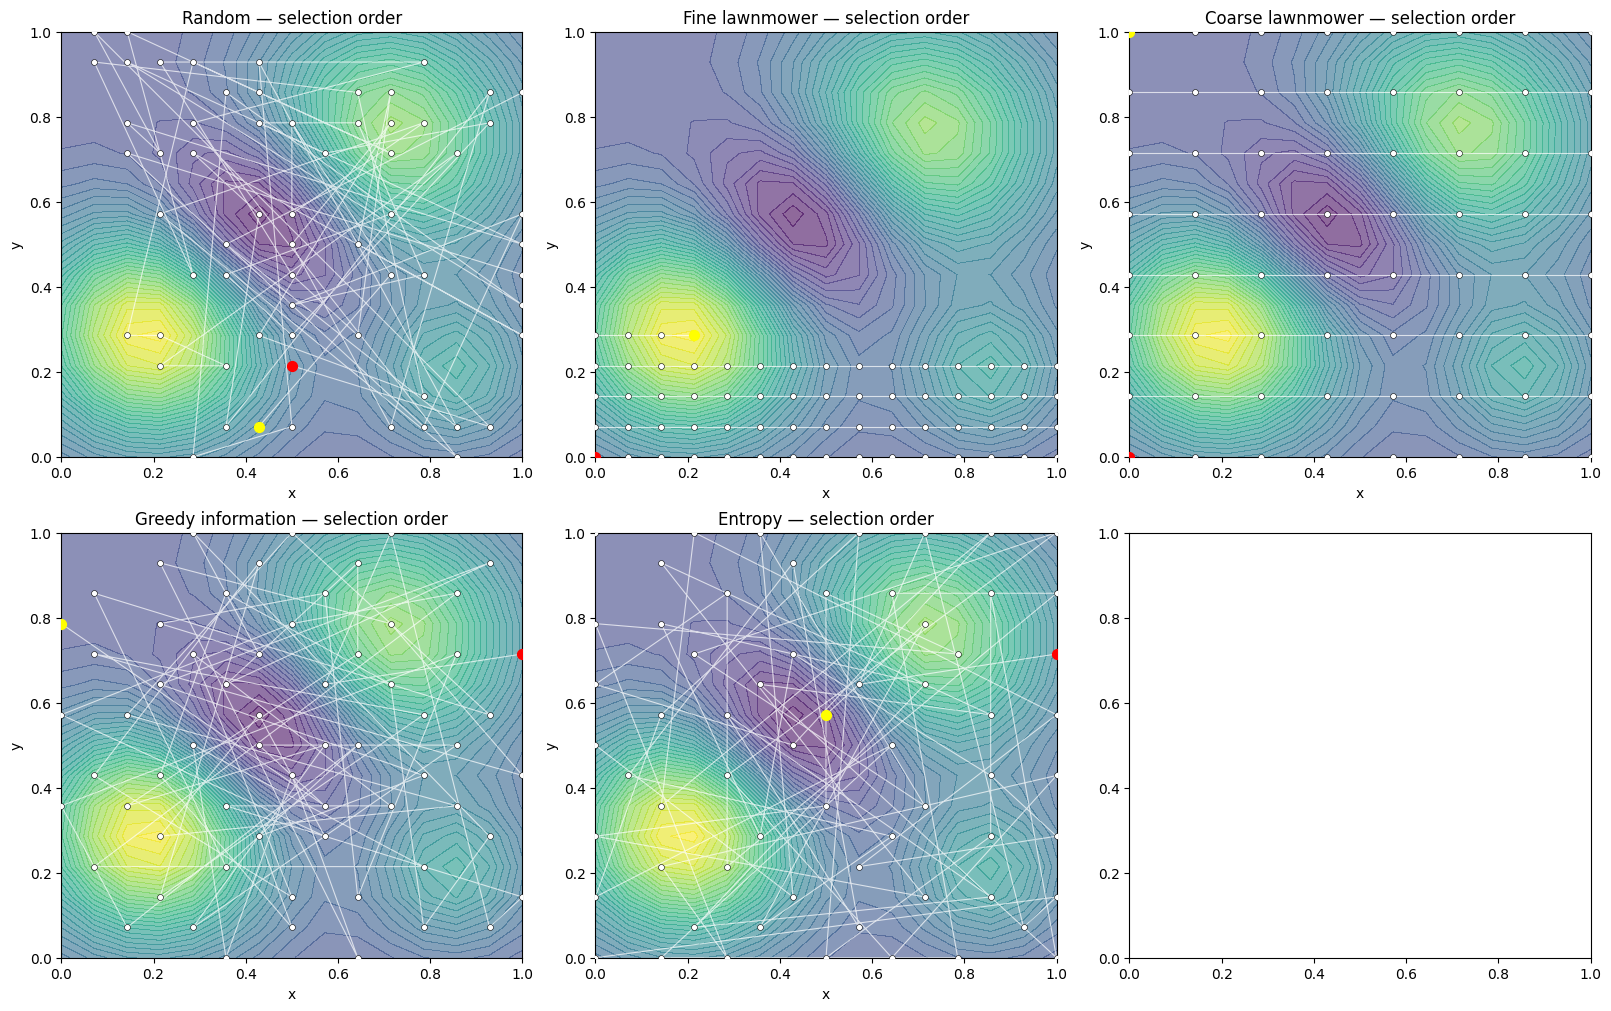

In [11]:
# -----------------------------
# 9a) Selected locations (no connecting path)
# -----------------------------

fig, axes = plt.subplots(2, 3, figsize=(16, 10), constrained_layout=True)
axes = axes.ravel()

for ax, (name, out) in zip(axes, final_budget_outputs.items()):
    pts = out['points']
    ax.contourf(x1_cand, x2_cand, candidate_field, levels=40, cmap='viridis')
    ax.scatter(pts[:, 0], pts[:, 1], c='white', edgecolor='black', linewidth=0.6, s=25, zorder=3)
    ax.set_title(f'{name} — selected locations')
    ax.set_xlabel('x')
    ax.set_ylabel('y')

plt.show()

# -----------------------------
# 9b) Selection-order paths
# -----------------------------

fig, axes = plt.subplots(2, 3, figsize=(16, 10), constrained_layout=True)
axes = axes.ravel()

for ax, (name, out) in zip(axes, final_budget_outputs.items()):
    pts = out['points']
    ax.contourf(x1_cand, x2_cand, candidate_field, levels=40, cmap='viridis', alpha=0.6)
    ax.plot(pts[:, 0], pts[:, 1], '-', linewidth=0.8, color='white', alpha=0.7)
    ax.scatter(pts[:, 0], pts[:, 1], c='white', edgecolor='black', linewidth=0.4, s=18, zorder=3)
    ax.scatter(pts[0, 0], pts[0, 1], c='red', s=50, zorder=4, label='start')
    ax.scatter(pts[-1, 0], pts[-1, 1], c='yellow', s=50, zorder=4, label='end')
    ax.set_title(f'{name} — selection order')
    ax.set_xlabel('x')
    ax.set_ylabel('y')

plt.show()

## 10) Greedy Marginal Information Gain

Tracks diminishing returns in the Krause-style greedy selection process.

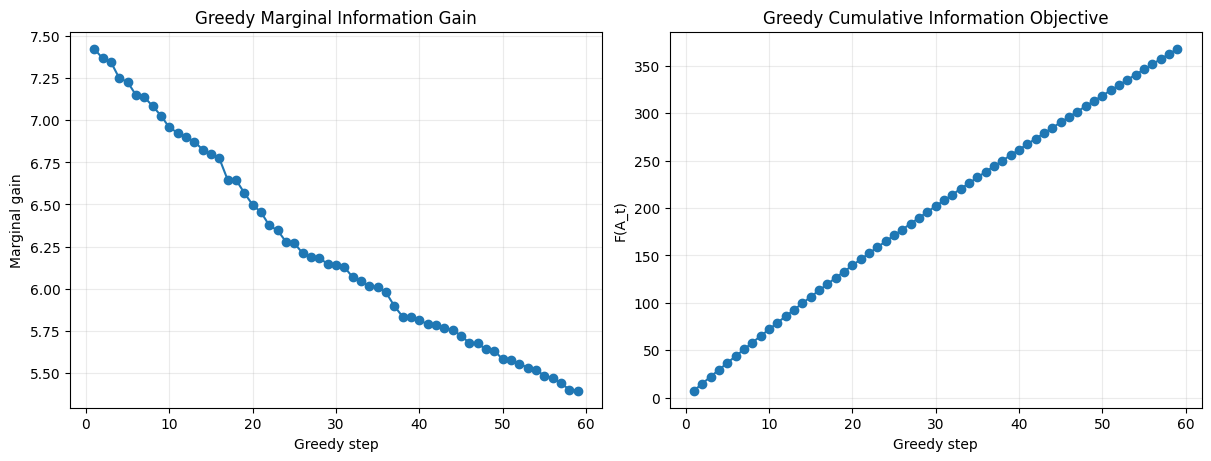

In [12]:
# -----------------------------
# 10) Greedy gain/objective traces
# -----------------------------

steps = np.arange(1, len(greedy_marginal_gain) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)

axes[0].plot(steps, greedy_marginal_gain, marker='o')
axes[0].set_title('Greedy Marginal Information Gain')
axes[0].set_xlabel('Greedy step')
axes[0].set_ylabel('Marginal gain')
axes[0].grid(alpha=0.25)

axes[1].plot(steps, greedy_objective, marker='o')
axes[1].set_title('Greedy Cumulative Information Objective')
axes[1].set_xlabel('Greedy step')
axes[1].set_ylabel('F(A_t)')
axes[1].grid(alpha=0.25)

plt.show()

## 11) Calibration Diagnostics at Final Budget

Error vs uncertainty scatter, empirical 95% coverage, and mean standardized residual.

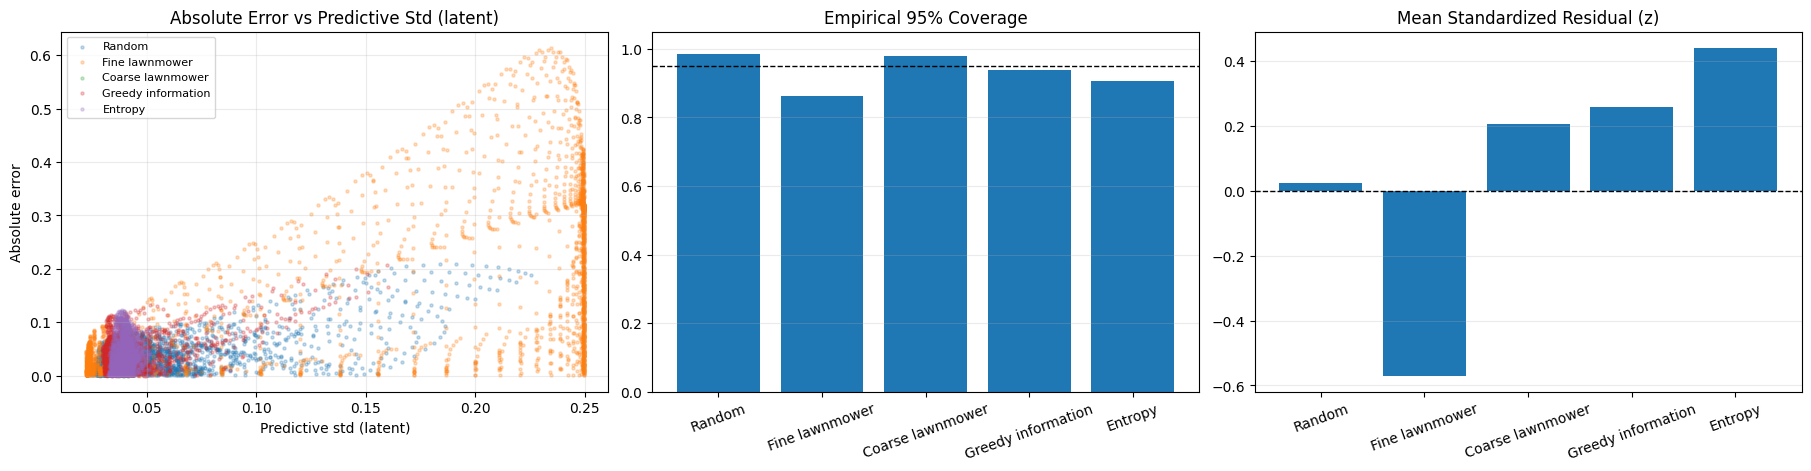

In [13]:
# -----------------------------
# 11) Calibration diagnostics
# -----------------------------

fig, axes = plt.subplots(1, 3, figsize=(18, 4.6), constrained_layout=True)

for name, out in final_budget_outputs.items():
    axes[0].scatter(out['std'], out['abs_error'], s=5, alpha=0.25, label=name)

axes[0].set_title('Absolute Error vs Predictive Std (latent)')
axes[0].set_xlabel('Predictive std (latent)')
axes[0].set_ylabel('Absolute error')
axes[0].grid(alpha=0.25)
axes[0].legend(fontsize=8)

dmax = results_df[results_df['Samples'] == max_budget].copy()
xpos = np.arange(len(dmax))

axes[1].bar(xpos, dmax['Coverage95'].values)
axes[1].axhline(0.95, linestyle='--', color='black', linewidth=1)
axes[1].set_xticks(xpos, dmax['Strategy'].values, rotation=20)
axes[1].set_ylim(0, 1.05)
axes[1].set_title('Empirical 95% Coverage')
axes[1].grid(axis='y', alpha=0.25)

axes[2].bar(xpos, dmax['MeanZ'].values)
axes[2].axhline(0.0, linestyle='--', color='black', linewidth=1)
axes[2].set_xticks(xpos, dmax['Strategy'].values, rotation=20)
axes[2].set_title('Mean Standardized Residual (z)')
axes[2].grid(axis='y', alpha=0.25)

plt.show()

## 12) Final Mean and Uncertainty Maps

Final dense-grid GP outputs for each strategy at the maximum sample budget.

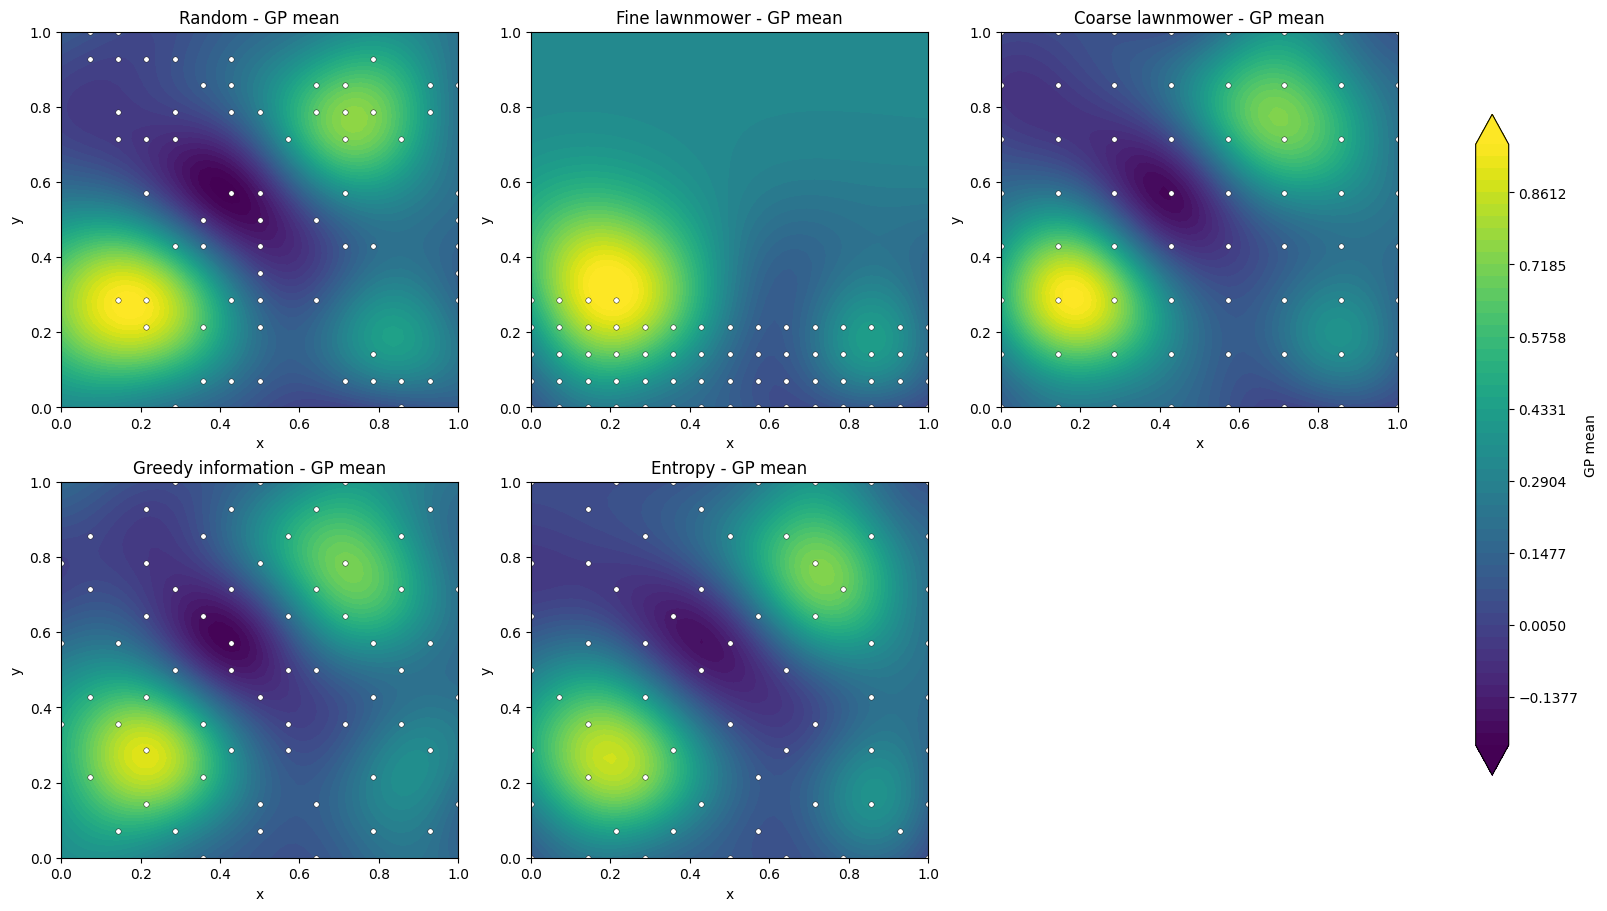

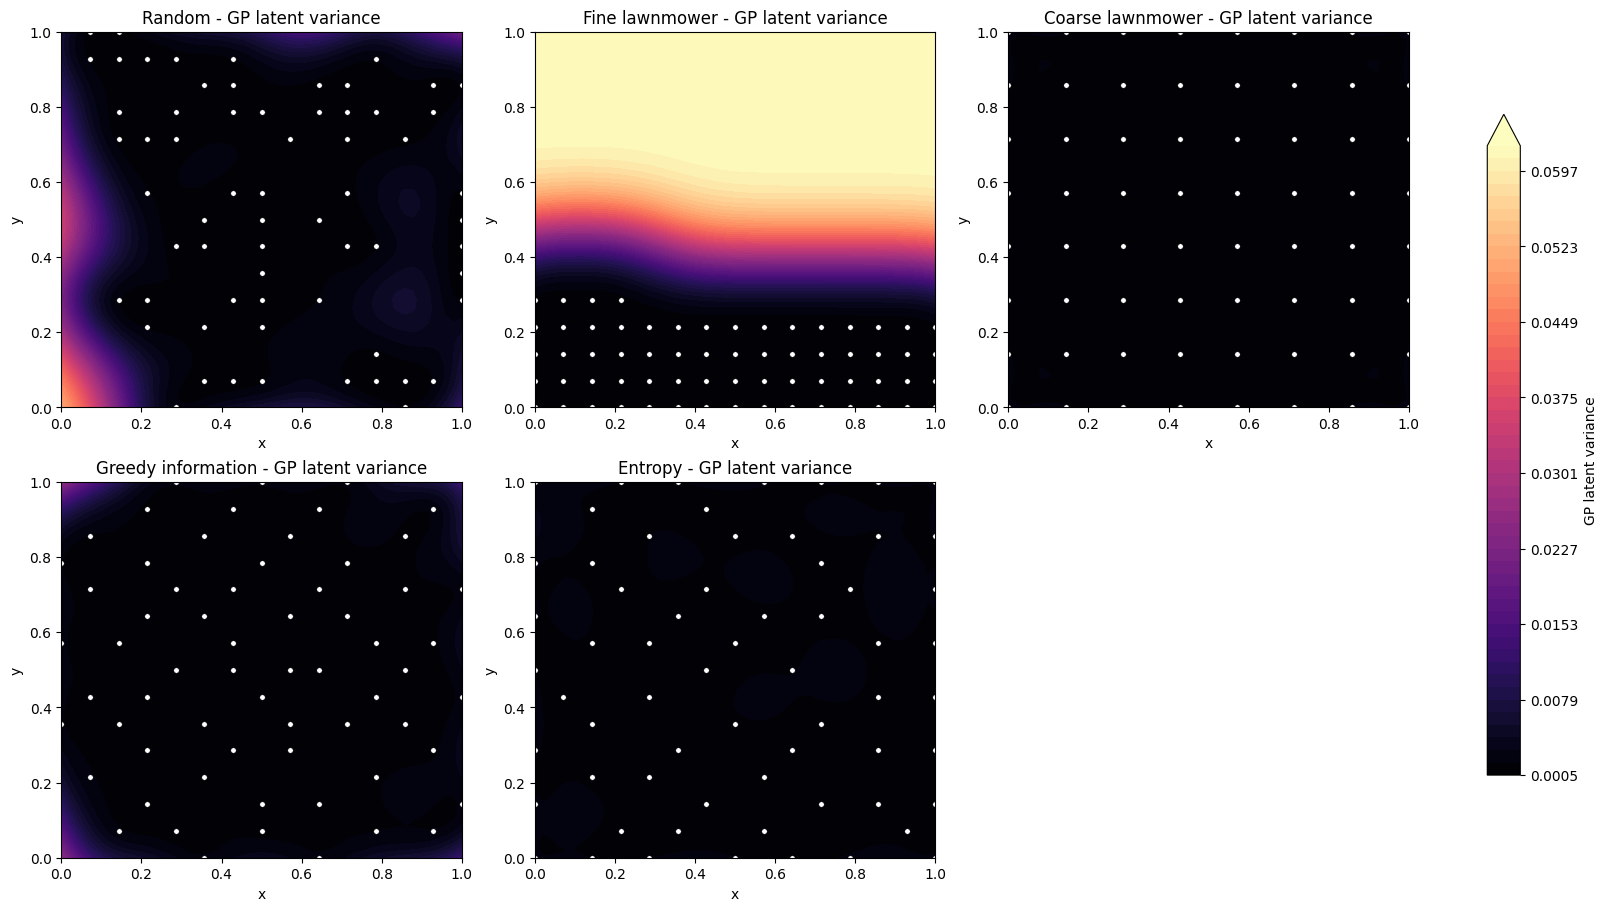

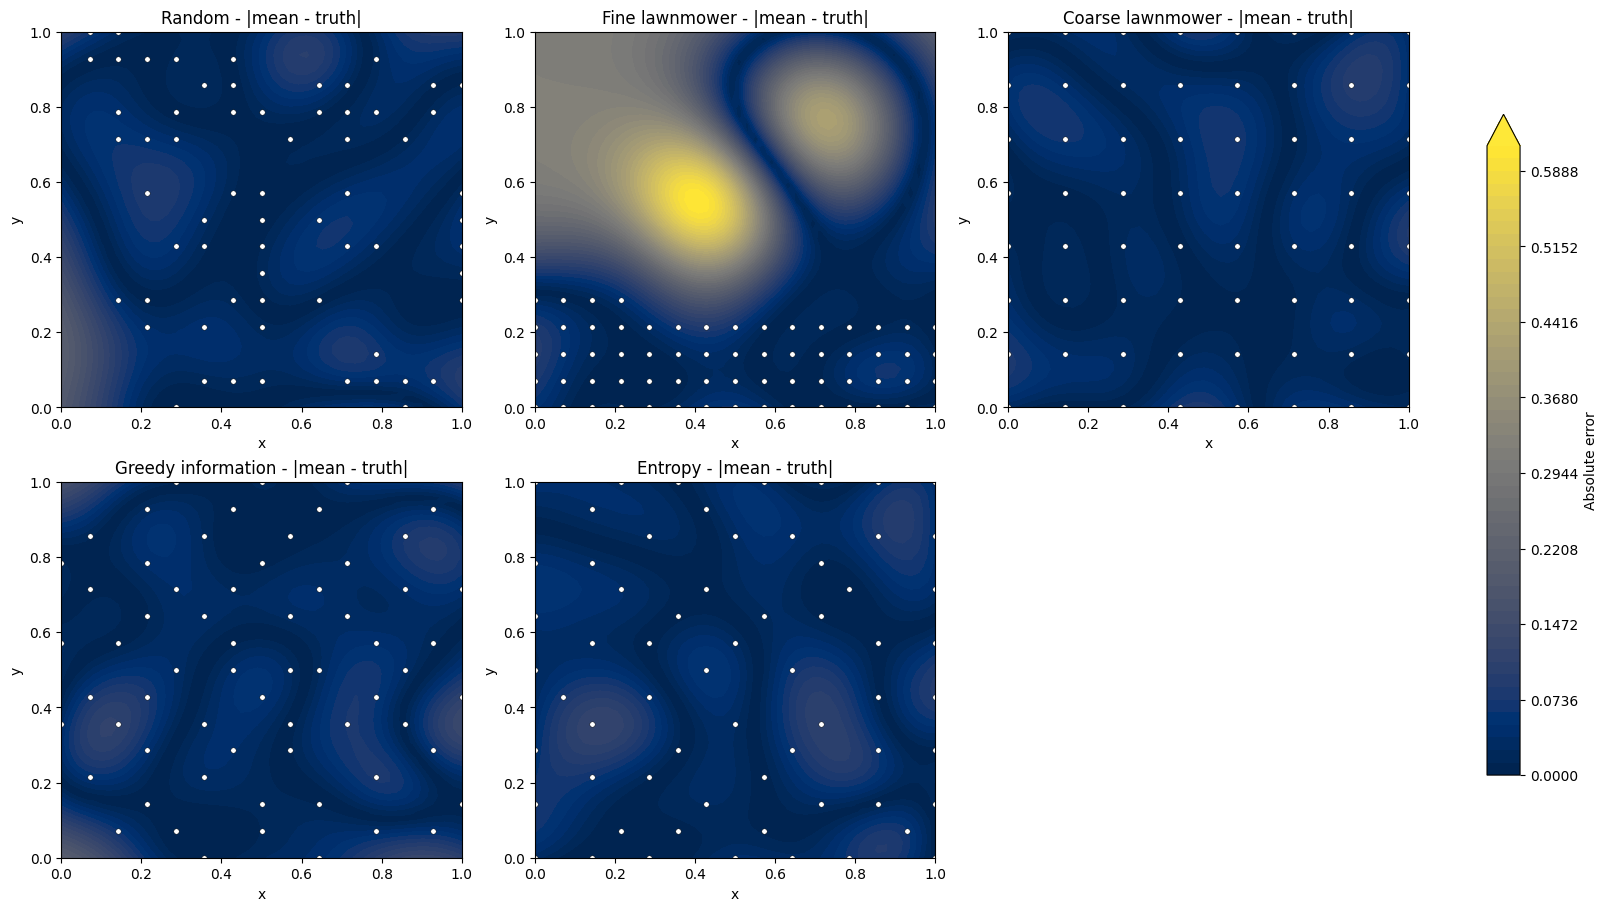

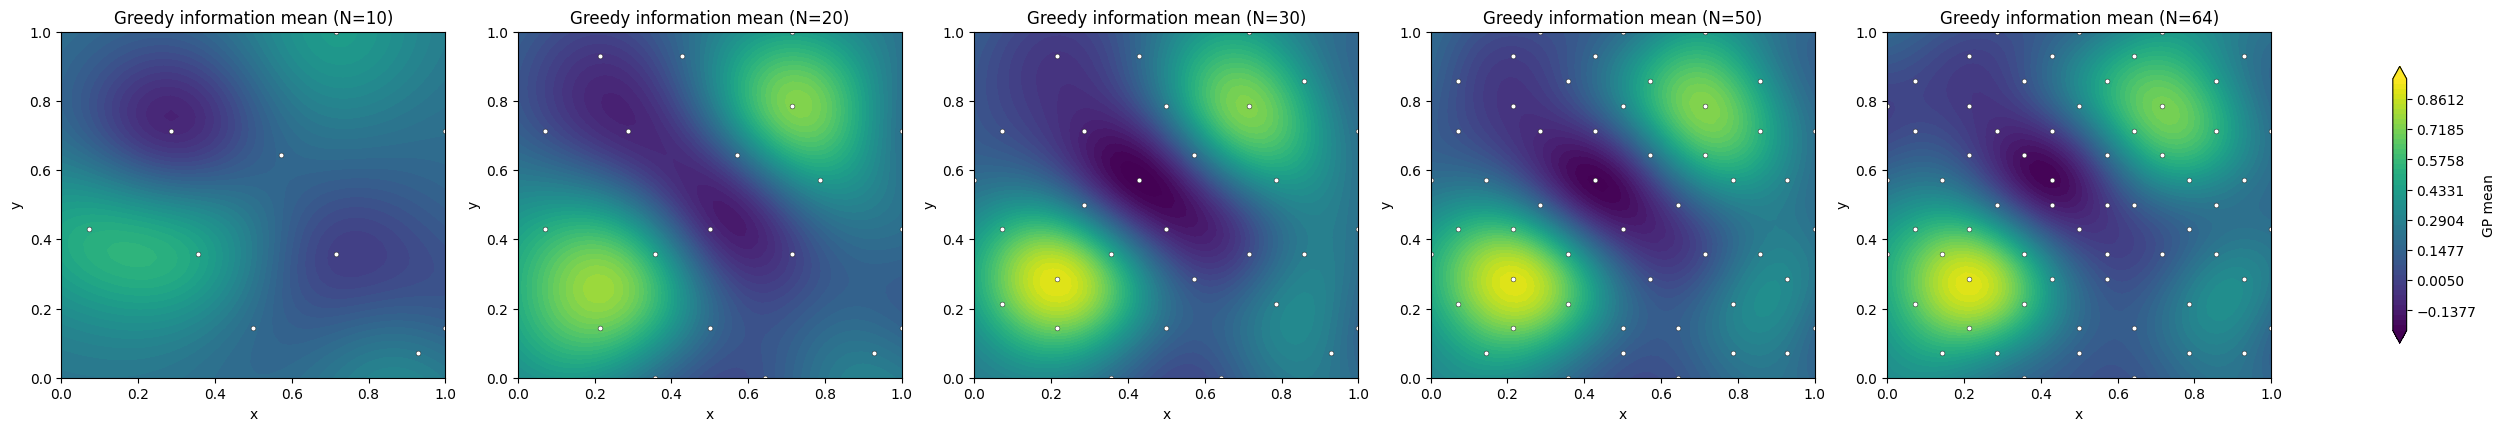

In [14]:
# -----------------------------
# 12) Mean and uncertainty maps
# -----------------------------

map_order = [
    'Random',
    'Fine lawnmower',
    'Coarse lawnmower',
    'Greedy information',
    'Entropy',
]

all_results = [
    {
        'name': name,
        'points': final_budget_outputs[name]['points'],
        'mean': final_budget_outputs[name]['mean'],
        'var': final_budget_outputs[name]['var'],
        'std': final_budget_outputs[name]['std'],
        'abs_error': final_budget_outputs[name]['abs_error'],
    }
    for name in map_order if name in final_budget_outputs
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9), constrained_layout=True)
axes = axes.ravel()

mean_vmin = eval_field.min()
mean_vmax = eval_field.max()
mean_levels = np.linspace(mean_vmin, mean_vmax, 51)

for ax, r in zip(axes, all_results):
    mean_grid = r['mean'].reshape(x1_eval.shape)
    c = ax.contourf(
        x1_eval, x2_eval, mean_grid, levels=mean_levels, cmap='viridis',
        vmin=mean_vmin, vmax=mean_vmax, extend='both'
    )
    ax.scatter(r['points'][:, 0], r['points'][:, 1], s=15, c='white', edgecolor='black', linewidth=0.3)
    ax.set_title(f"{r['name']} - GP mean")
    ax.set_xlabel('x')
    ax.set_ylabel('y')

for k in range(len(all_results), len(axes)):
    axes[k].axis('off')

fig.colorbar(c, ax=axes.tolist(), shrink=0.8, label='GP mean')
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(16, 9), constrained_layout=True)
axes = axes.ravel()

all_var = np.concatenate([r['var'] for r in all_results])
var_vmin = float(np.min(all_var))
var_vmax = float(np.max(all_var))
var_levels = np.linspace(var_vmin, var_vmax, 51)

for ax, r in zip(axes, all_results):
    var_grid = r['var'].reshape(x1_eval.shape)
    c = ax.contourf(
        x1_eval, x2_eval, var_grid, levels=var_levels, cmap='magma',
        vmin=var_vmin, vmax=var_vmax, extend='max'
    )
    ax.scatter(r['points'][:, 0], r['points'][:, 1], s=15, c='white', edgecolor='black', linewidth=0.3)
    ax.set_title(f"{r['name']} - GP latent variance")
    ax.set_xlabel('x')
    ax.set_ylabel('y')

for k in range(len(all_results), len(axes)):
    axes[k].axis('off')

fig.colorbar(c, ax=axes.tolist(), shrink=0.8, label='GP latent variance')
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(16, 9), constrained_layout=True)
axes = axes.ravel()
all_err = np.concatenate([r['abs_error'] for r in all_results])
err_vmin = float(np.min(all_err))
err_vmax = float(np.max(all_err))
err_levels = np.linspace(err_vmin, err_vmax, 51)

for ax, r in zip(axes, all_results):
    err_grid = r['abs_error'].reshape(x1_eval.shape)
    c = ax.contourf(
        x1_eval, x2_eval, err_grid, levels=err_levels, cmap='cividis',
        vmin=err_vmin, vmax=err_vmax, extend='max'
    )
    ax.scatter(r['points'][:, 0], r['points'][:, 1], s=15, c='white', edgecolor='black', linewidth=0.3)
    ax.set_title(f"{r['name']} - |mean - truth|")
    ax.set_xlabel('x')
    ax.set_ylabel('y')

for k in range(len(all_results), len(axes)):
    axes[k].axis('off')

fig.colorbar(c, ax=axes.tolist(), shrink=0.8, label='Absolute error')
plt.show()

# Budget-evolution view for one smart strategy
evo_strategy = 'Greedy information'
fig, axes = plt.subplots(1, len(sample_budgets), figsize=(5 * len(sample_budgets), 4.2), constrained_layout=True)
if len(sample_budgets) == 1:
    axes = [axes]

for ax, n in zip(axes, sample_budgets):
    evo_mean = budget_outputs[evo_strategy][n]['mean'].reshape(x1_eval.shape)
    c = ax.contourf(
        x1_eval, x2_eval, evo_mean, levels=mean_levels, cmap='viridis',
        vmin=mean_vmin, vmax=mean_vmax, extend='both'
    )
    pts = budget_outputs[evo_strategy][n]['points']
    ax.scatter(pts[:, 0], pts[:, 1], s=12, c='white', edgecolor='black', linewidth=0.3)
    ax.set_title(f"{evo_strategy} mean (N={n})")
    ax.set_xlabel('x')
    ax.set_ylabel('y')

fig.colorbar(c, ax=axes, shrink=0.8, label='GP mean')
plt.show()

## 13) Optional 3D Comparison (Final Budget)

True field vs reconstructed mean surfaces for each strategy.

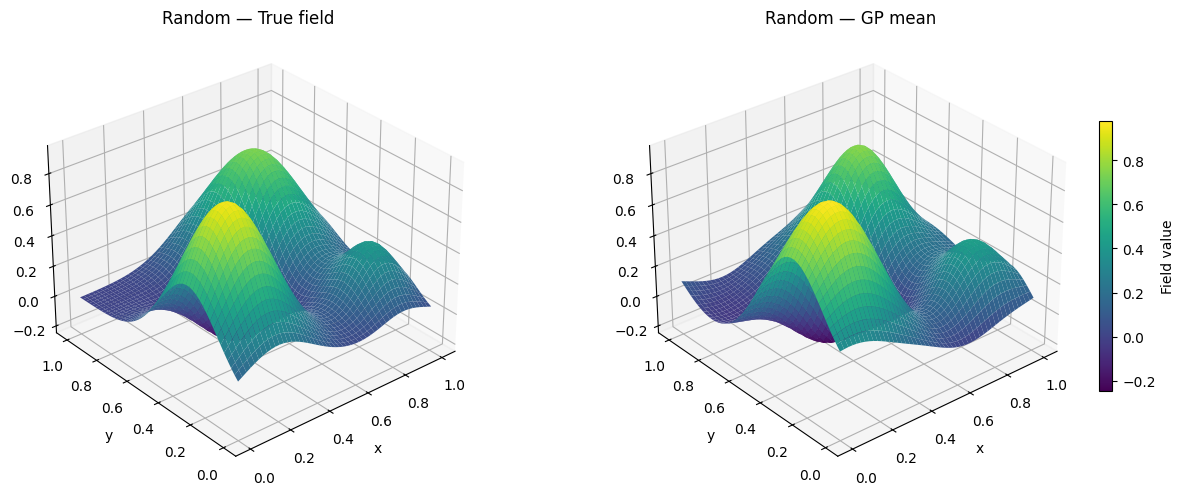

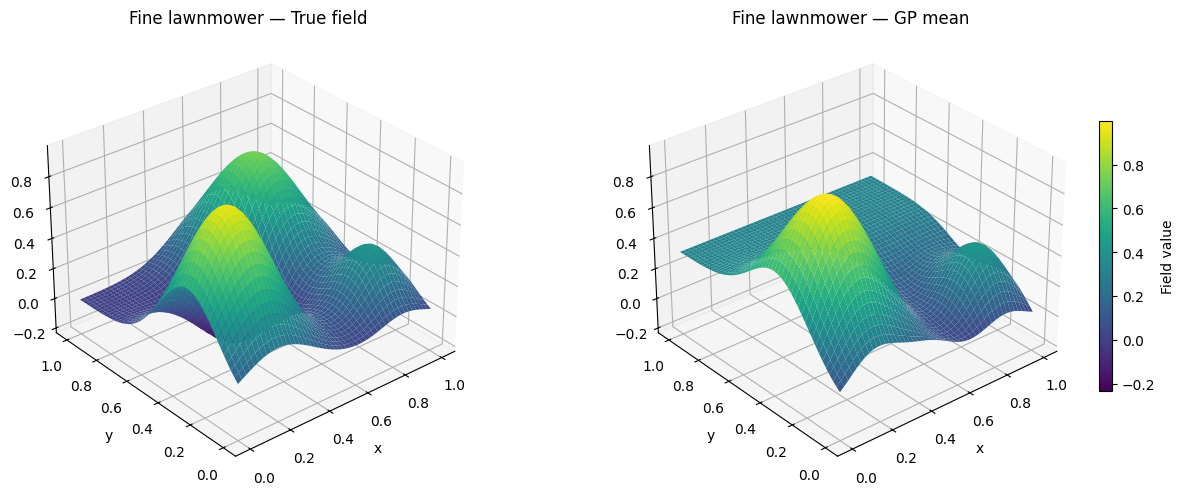

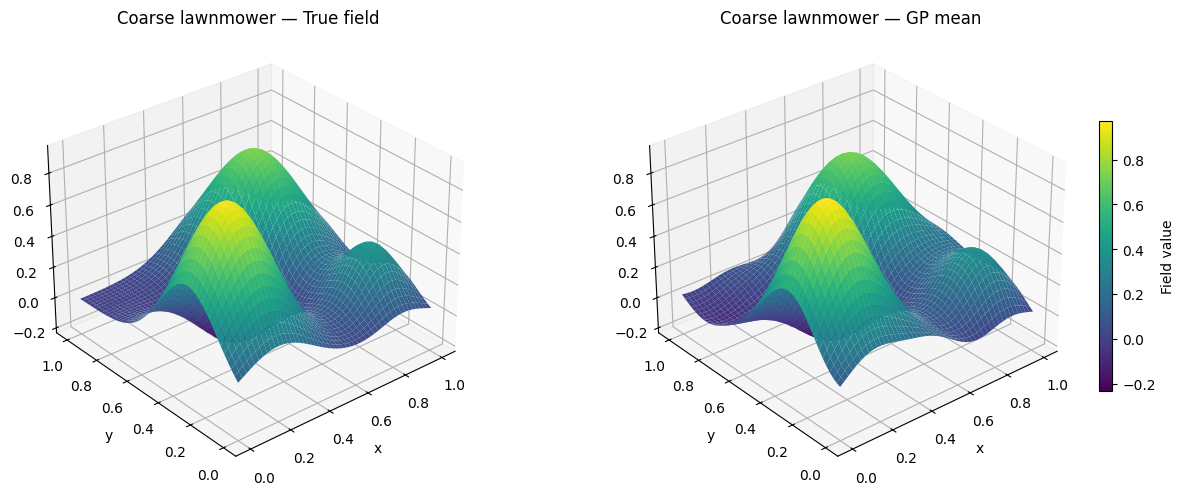

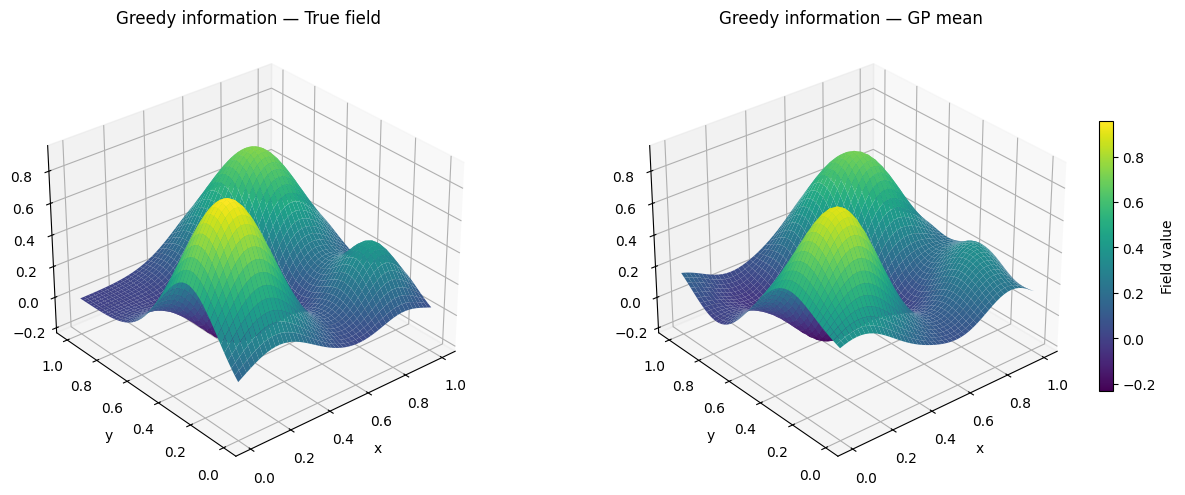

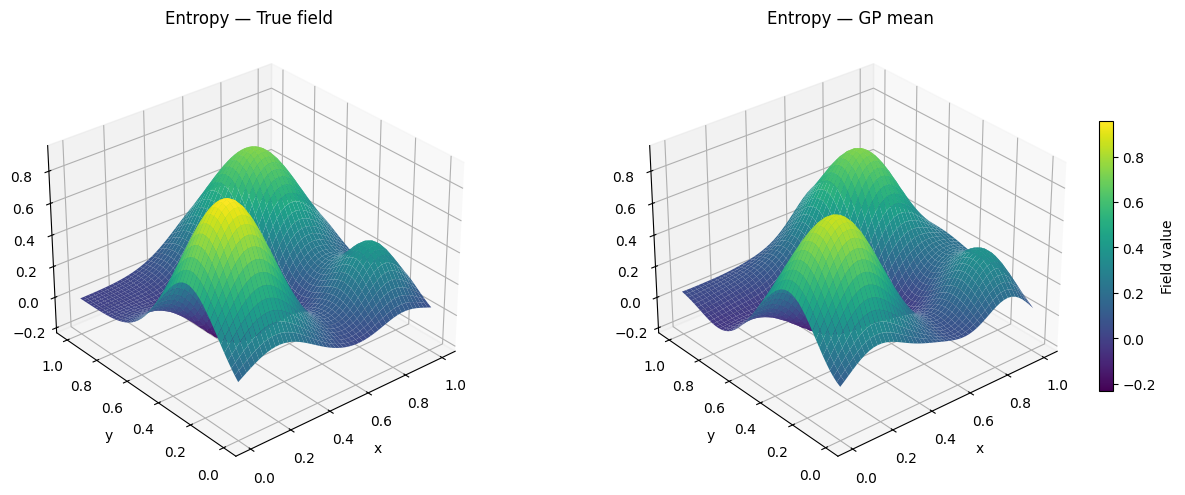

In [15]:
# -----------------------------
# 13) 3D surfaces
# -----------------------------

from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
from matplotlib.colors import Normalize

for name, out in final_budget_outputs.items():
    mean_grid = out['mean'].reshape(x1_eval.shape)

    zmin = float(min(eval_field.min(), mean_grid.min()))
    zmax = float(max(eval_field.max(), mean_grid.max()))
    norm = Normalize(vmin=zmin, vmax=zmax)

    fig = plt.figure(figsize=(13, 4.8), constrained_layout=True)
    ax1 = fig.add_subplot(1, 2, 1, projection='3d')
    ax2 = fig.add_subplot(1, 2, 2, projection='3d')

    s1 = ax1.plot_surface(x1_eval, x2_eval, eval_field,
                          cmap='viridis', norm=norm, linewidth=0)
    s2 = ax2.plot_surface(x1_eval, x2_eval, mean_grid,
                          cmap='viridis', norm=norm, linewidth=0)

    ax1.set_zlim(zmin, zmax)
    ax2.set_zlim(zmin, zmax)

    for ax in (ax1, ax2):
        ax.view_init(elev=30, azim=-130)
        ax.set_xlabel('x')
        ax.set_ylabel('y')

    ax1.set_title(f'{name} — True field')
    ax2.set_title(f'{name} — GP mean')

    # Shared colorbar on the right margin
    sm = plt.cm.ScalarMappable(cmap='viridis', norm=norm)
    sm.set_array([])
    fig.colorbar(sm, ax=[ax1, ax2], shrink=0.6, pad=0.02, label='Field value')
    plt.show()

## 13.1) Optional Multi-Budget Sweep (Controlled)

This sweep uses the same candidate-domain selection and shared noise map logic as the main experiment.

In [16]:
run_budget_sweep = False
budget_list = list(sample_budgets)

if run_budget_sweep:
    rows = []
    for budget in budget_list:
        print(f'Running budget {budget}...')

        # Reuse nested pools from Section 6 for consistent budget progression
        random_b_points = random_pool[:budget]
        fine_b_points = fine_pool[:budget]
        coarse_b_points = coarse_pool[:budget]
        greedy_points_b = greedy_pool[:budget]
        ent_points_b = entropy_pool[:budget]

        _, random_b_noisy = measure_candidate_points(random_b_points, noisy_lookup)
        _, fine_b_noisy = measure_candidate_points(fine_b_points, noisy_lookup)
        _, coarse_b_noisy = measure_candidate_points(coarse_b_points, noisy_lookup)
        _, greedy_noisy_b = measure_candidate_points(greedy_points_b, noisy_lookup)
        _, ent_noisy_b = measure_candidate_points(ent_points_b, noisy_lookup)

        random_b = fit_gp_predict(
            random_b_points, random_b_noisy,
            mode=evaluation_gp_mode, standardize=standardize_targets,
        )
        fine_b = fit_gp_predict(
            fine_b_points, fine_b_noisy,
            mode=evaluation_gp_mode, standardize=standardize_targets,
        )
        coarse_b = fit_gp_predict(
            coarse_b_points, coarse_b_noisy,
            mode=evaluation_gp_mode, standardize=standardize_targets,
        )
        greedy_b = fit_gp_predict(
            greedy_points_b, greedy_noisy_b,
            mode=evaluation_gp_mode, standardize=standardize_targets,
        )
        ent_b = fit_gp_predict(
            ent_points_b, ent_noisy_b,
            mode=evaluation_gp_mode, standardize=standardize_targets,
        )

        for name, rr, pts in [
            ('Random', random_b, random_b_points),
            ('Fine lawnmower', fine_b, fine_b_points),
            ('Coarse lawnmower', coarse_b, coarse_b_points),
            ('Greedy information', greedy_b, greedy_points_b),
            ('Entropy', ent_b, ent_points_b),
        ]:
            rows.append({
                'Budget': budget,
                'Strategy': name,
                'RMSE': rr['rmse'],
                'Mean Variance': rr['mean_var'],
                'Selection-Order Path Length': path_length(pts),
            })

    budget_df = pd.DataFrame(rows)
    display(budget_df.head())

    # Keep one representative smart method in sweep plots
    budget_plot_df = budget_df.copy()

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), constrained_layout=True)

    for strategy, grp in budget_plot_df.groupby('Strategy'):
        grp = grp.sort_values('Budget')
        axes[0].plot(grp['Budget'], grp['RMSE'], marker='o', label=strategy)
        axes[1].plot(grp['Budget'], grp['Mean Variance'], marker='o', label=strategy)
        axes[2].plot(grp['Budget'], grp['Selection-Order Path Length'], marker='o', label=strategy)

    axes[0].set_title('RMSE vs budget')
    axes[1].set_title('Mean latent variance vs budget')
    axes[2].set_title('Selection-order path length vs budget')

    for ax in axes:
        ax.set_xlabel('Sample budget')
        ax.grid(alpha=0.2)

    axes[0].legend(fontsize=7)
    plt.show()
else:
    print('Budget sweep is disabled. Set run_budget_sweep=True to execute.')

Budget sweep is disabled. Set run_budget_sweep=True to execute.


## 13.2) Output-Scale Comparison (Oracle vs Pilot Estimate)

For synthetic validation we compare fixed-GP reconstruction using:

- Oracle output scale from full field variance (not available in deployment).
- Pilot-estimated output scale from shared pilot measurements (deployment-compatible).

Both runs use identical selected points and identical fixed lengthscale/noise.

,Mode,OutputScaleUsed,RMSE,MeanVariance,Coverage95,ErrUncCorr
0,oracle-field-variance,0.062177,0.046048,0.001960,0.9384,0.513760
1,pilot-estimated-variance,0.014043,0.048688,0.001188,0.8308,0.369719


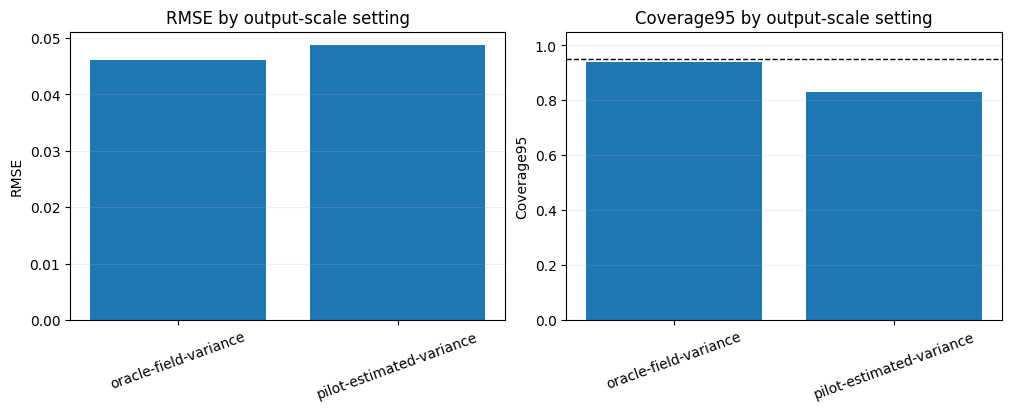

In [17]:
def evaluate_fixed_mode_with_outputscale(points, noisy_values, outputscale_value):
    global greedy_outputscale
    old_outputscale = greedy_outputscale
    greedy_outputscale = float(outputscale_value)
    try:
        out = fit_gp_predict(
            points, noisy_values,
            mode='fixed',
            standardize=standardize_targets,
        )
    finally:
        greedy_outputscale = old_outputscale
    return out

pilot_measurements = np.array([
    noisy_lookup[_point_key(p)] for p in pilot_points
])

oracle_outputscale = float(np.var(eval_field))
pilot_outputscale = max(float(np.var(pilot_measurements, ddof=1)), 1e-4)

greedy_points_max = greedy_pool[:max_budget]
greedy_noisy_max = strategy_noisy_pools['Greedy information'][:max_budget]

comparison_rows = []
for label, scale in [
    ('oracle-field-variance', oracle_outputscale),
    ('pilot-estimated-variance', pilot_outputscale),
]:
    out = evaluate_fixed_mode_with_outputscale(greedy_points_max, greedy_noisy_max, scale)
    comparison_rows.append({
        'Mode': label,
        'OutputScaleUsed': scale,
        'RMSE': out['rmse'],
        'MeanVariance': out['mean_var'],
        'Coverage95': out['coverage_95'],
        'ErrUncCorr': out['corr_err_unc'],
    })

outputscale_comparison_df = pd.DataFrame(comparison_rows)
display(outputscale_comparison_df)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
axes[0].bar(outputscale_comparison_df['Mode'], outputscale_comparison_df['RMSE'])
axes[0].set_title('RMSE by output-scale setting')
axes[0].set_ylabel('RMSE')
axes[0].tick_params(axis='x', rotation=20)
axes[0].grid(axis='y', alpha=0.2)

axes[1].bar(outputscale_comparison_df['Mode'], outputscale_comparison_df['Coverage95'])
axes[1].axhline(0.95, color='black', linestyle='--', linewidth=1)
axes[1].set_title('Coverage95 by output-scale setting')
axes[1].set_ylabel('Coverage95')
axes[1].set_ylim(0, 1.05)
axes[1].tick_params(axis='x', rotation=20)
axes[1].grid(axis='y', alpha=0.2)
plt.show()

## 13.3) Random Baseline Over 20 Seeds

Random sampling is stochastic. This section estimates mean and standard deviation across 20 random seeds for RMSE, mean variance, and selection-order path length.

,Samples,RMSE_mean,RMSE_std,MeanVariance_mean,MeanVariance_std,PathLength_mean,PathLength_std
0,10,0.192638,0.039896,0.029736,0.002995,5.099743,0.771373
1,20,0.121307,0.033224,0.015445,0.002127,10.959237,1.294837
2,30,0.093970,0.029766,0.009153,0.001172,16.703616,1.641932
3,50,0.057191,0.009557,0.004084,0.000709,27.516024,1.685079
4,64,0.047231,0.007152,0.002734,0.000463,35.873235,2.022783


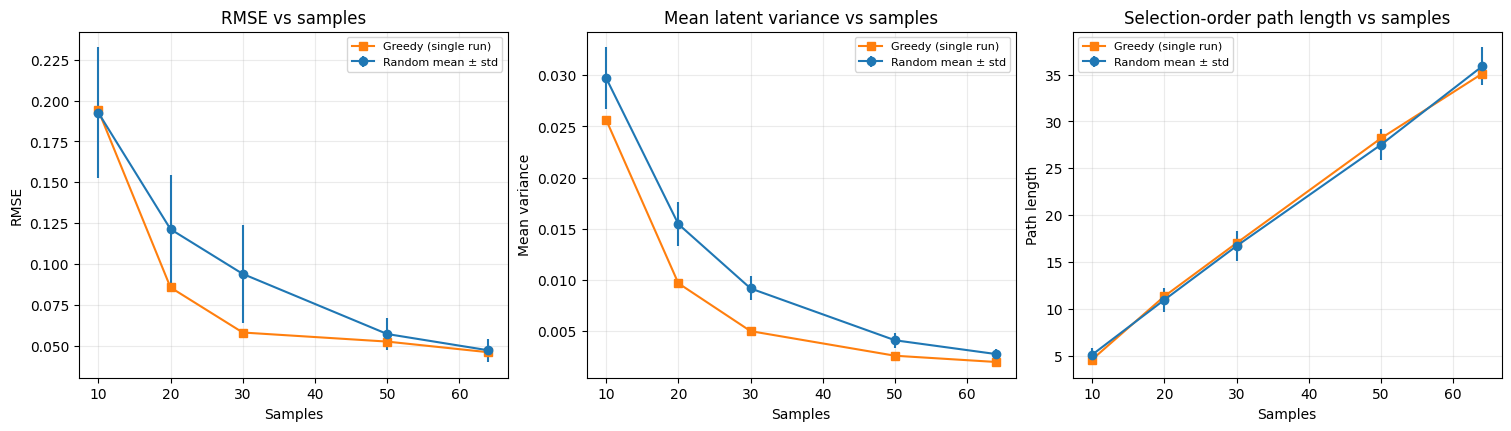

In [18]:
random_seed_list = list(range(20))
random_mc_rows = []

for seed_i in random_seed_list:
    rng_i = np.random.default_rng(1000 + seed_i)
    random_pool_i = random_sampler(candidate_points, n_samples=max_budget, rng=rng_i)
    _, random_noisy_pool_i = measure_candidate_points(random_pool_i, noisy_lookup)

    for n in sample_budgets:
        pts_i = random_pool_i[:n]
        noisy_i = random_noisy_pool_i[:n]
        out_i = fit_gp_predict(
            pts_i, noisy_i,
            mode=evaluation_gp_mode,
            standardize=standardize_targets,
        )

        random_mc_rows.append({
            'Seed': seed_i,
            'Samples': n,
            'RMSE': out_i['rmse'],
            'MeanVariance': out_i['mean_var'],
            'PathLength': path_length(pts_i),
        })

random_mc_df = pd.DataFrame(random_mc_rows)
random_mc_summary = random_mc_df.groupby('Samples').agg(
    RMSE_mean=('RMSE', 'mean'),
    RMSE_std=('RMSE', 'std'),
    MeanVariance_mean=('MeanVariance', 'mean'),
    MeanVariance_std=('MeanVariance', 'std'),
    PathLength_mean=('PathLength', 'mean'),
    PathLength_std=('PathLength', 'std'),
).reset_index()

smart_curve = (
    results_df[results_df['Strategy'] == 'Greedy information'][['Samples', 'RMSE', 'MeanVariance', 'PathLength']]
    .sort_values('Samples')
    .reset_index(drop=True)
)

display(random_mc_summary)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)

axes[0].errorbar(
    random_mc_summary['Samples'],
    random_mc_summary['RMSE_mean'],
    yerr=random_mc_summary['RMSE_std'],
    fmt='-o',
    label='Random mean ± std',
)
axes[0].plot(smart_curve['Samples'], smart_curve['RMSE'], '-s', label='Greedy (single run)')
axes[0].set_title('RMSE vs samples')
axes[0].set_xlabel('Samples')
axes[0].set_ylabel('RMSE')
axes[0].grid(alpha=0.25)
axes[0].legend(fontsize=8)

axes[1].errorbar(
    random_mc_summary['Samples'],
    random_mc_summary['MeanVariance_mean'],
    yerr=random_mc_summary['MeanVariance_std'],
    fmt='-o',
    label='Random mean ± std',
)
axes[1].plot(smart_curve['Samples'], smart_curve['MeanVariance'], '-s', label='Greedy (single run)')
axes[1].set_title('Mean latent variance vs samples')
axes[1].set_xlabel('Samples')
axes[1].set_ylabel('Mean variance')
axes[1].grid(alpha=0.25)
axes[1].legend(fontsize=8)

axes[2].errorbar(
    random_mc_summary['Samples'],
    random_mc_summary['PathLength_mean'],
    yerr=random_mc_summary['PathLength_std'],
    fmt='-o',
    label='Random mean ± std',
)
axes[2].plot(smart_curve['Samples'], smart_curve['PathLength'], '-s', label='Greedy (single run)')
axes[2].set_title('Selection-order path length vs samples')
axes[2].set_xlabel('Samples')
axes[2].set_ylabel('Path length')
axes[2].grid(alpha=0.25)
axes[2].legend(fontsize=8)

plt.show()

## 13.4) Cold-Start Experiment: Two Randomly Placed Sensors

A deployment-style cold start: instead of a 5-point pilot, drop **two randomly
placed sensors**, take one measurement at each, then let the GP sample sequentially
"as normal". This compares the 2-sensor cold start against the main 5-pilot run for
both the entropy and greedy-MI strategies — does a smaller starting set hurt the
reconstruction, or does sequential active sampling recover quickly?

,Strategy,Samples,RMSE,MeanVariance,PathLength,Coverage95
0,Greedy information (2-sensor),10,0.077111,0.023004,5.005340,1.0000
1,Entropy (2-sensor),10,0.252506,0.030575,7.545380,0.8640
2,Greedy information (2-sensor),20,0.056620,0.007915,11.752614,0.9976
3,Entropy (2-sensor),20,0.104640,0.012702,15.715066,0.9788
4,Greedy information (2-sensor),30,0.052289,0.004841,17.662894,0.9992
5,Entropy (2-sensor),30,0.059865,0.004880,22.239388,0.9840
6,Greedy information (2-sensor),50,0.043692,0.002788,27.612584,0.9636
7,Entropy (2-sensor),50,0.044123,0.002042,36.231429,0.9672
8,Entropy (2-sensor),64,0.038024,0.001570,43.388308,0.9680
9,Greedy information (2-sensor),64,0.044101,0.001906,34.166009,0.9412


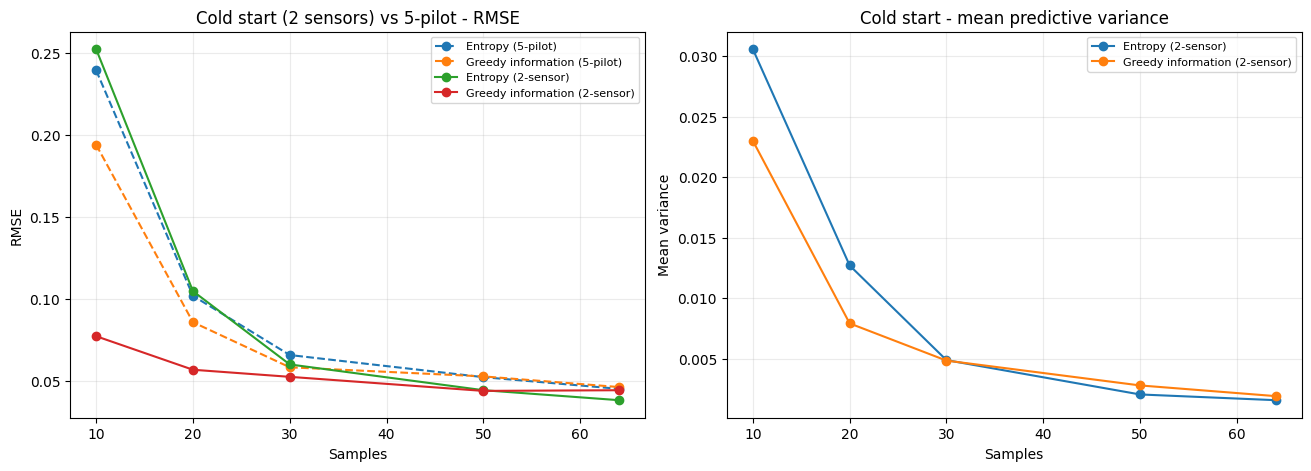

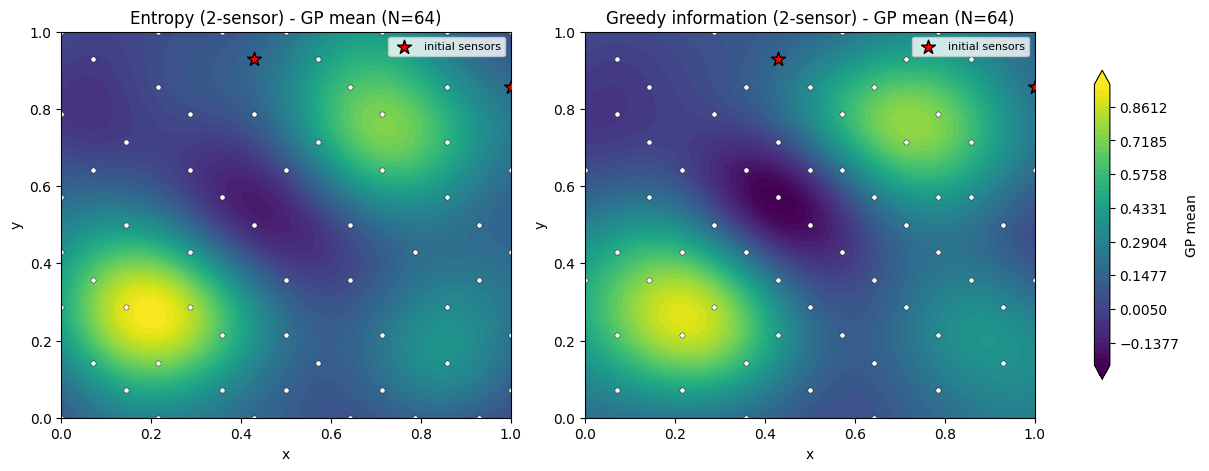

In [19]:
# -----------------------------
# 13.4) Two-sensor cold start
# -----------------------------
two_sensor_k = 2
two_sensor_idx = rng.choice(len(candidate_points), size=two_sensor_k, replace=False)
two_sensor_points = candidate_points[two_sensor_idx]

# Greedy MI and entropy active, both seeded with the SAME two sensors.
_, ts_greedy_pool, ts_greedy_gain, ts_greedy_obj = greedy_information_sampler(
    max_budget, initial_indices=list(two_sensor_idx)
)
ts_entropy_pool, _, _ = sequential_active_sampler(
    max_budget, acquisition='entropy', initial_points=two_sensor_points, noisy_lookup=noisy_lookup
)

ts_pools = {
    'Entropy (2-sensor)': ts_entropy_pool,
    'Greedy information (2-sensor)': ts_greedy_pool,
}

ts_records, ts_final = [], {}
for name, pool in ts_pools.items():
    _, noisy_pool = measure_candidate_points(pool, noisy_lookup)
    for n in sample_budgets:
        pts = pool[:n]
        out = fit_gp_predict(pts, noisy_pool[:n], mode=evaluation_gp_mode, standardize=standardize_targets)
        ts_records.append({
            'Strategy': name, 'Samples': n, 'RMSE': out['rmse'],
            'MeanVariance': out['mean_var'], 'PathLength': path_length(pts),
            'Coverage95': out['coverage_95'],
        })
        if n == max_budget:
            ts_final[name] = {'points': pts, 'mean': out['mean']}

ts_df = pd.DataFrame(ts_records)
display(ts_df.sort_values(['Samples', 'RMSE']).reset_index(drop=True))

# Curves: cold start vs the 5-pilot main run
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), constrained_layout=True)
for main_name in ['Entropy', 'Greedy information']:
    m = results_df[results_df['Strategy'] == main_name].sort_values('Samples')
    axes[0].plot(m['Samples'], m['RMSE'], '--o', label=f'{main_name} (5-pilot)')
for name in ts_pools:
    g = ts_df[ts_df['Strategy'] == name].sort_values('Samples')
    axes[0].plot(g['Samples'], g['RMSE'], '-o', label=name)
    axes[1].plot(g['Samples'], g['MeanVariance'], '-o', label=name)
axes[0].set_title('Cold start (2 sensors) vs 5-pilot - RMSE')
axes[0].set_xlabel('Samples'); axes[0].set_ylabel('RMSE')
axes[1].set_title('Cold start - mean predictive variance')
axes[1].set_xlabel('Samples'); axes[1].set_ylabel('Mean variance')
for a in axes:
    a.grid(alpha=0.25); a.legend(fontsize=8)
plt.show()

# Final GP-mean maps for the cold-start strategies (initial sensors marked with stars)
mean_levels = np.linspace(eval_field.min(), eval_field.max(), 51)
fig, axes = plt.subplots(1, len(ts_final), figsize=(6 * len(ts_final), 4.6), constrained_layout=True)
axes = np.atleast_1d(axes)
c = None
for ax, (name, out) in zip(axes, ts_final.items()):
    c = ax.contourf(x1_eval, x2_eval, out['mean'].reshape(x1_eval.shape),
                    levels=mean_levels, cmap='viridis', extend='both')
    ax.scatter(out['points'][:, 0], out['points'][:, 1], s=14, c='white', edgecolor='black', linewidth=0.3)
    ax.scatter(two_sensor_points[:, 0], two_sensor_points[:, 1], s=110, marker='*',
               c='red', edgecolor='black', zorder=5, label='initial sensors')
    ax.set_title(f'{name} - GP mean (N={max_budget})')
    ax.set_xlabel('x'); ax.set_ylabel('y'); ax.legend(fontsize=8)
fig.colorbar(c, ax=axes.tolist(), shrink=0.8, label='GP mean')
plt.show()